# Imports

In [2]:
import numpy as np
import numpy.matlib as matlib
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import plotly.graph_objects as go
#from plotly.subplots import make_subplots
import seaborn as sns
import pickle
import datetime

import os

import torch
torch._dynamo.config.capture_dynamic_output_shape_ops = True
torch._dynamo.config.capture_func_transforms = True
import scipy 

## from pymindy.dataset import PartitionDataset, create_synth_MINDy, create_synth_HMMINDy, simHMMINDy

# BEGIN NEW CODE - JAKE
# pop_layout() defines the channel-major population layout ([e1 i1 e2 i2 ...] per
# channel) used by create_synth_data.py and hmmindy_core.py; build_chan_mask() and
# build_W_mask() build the W mask directly in that layout
from pymindy.dataset.create_synth_data import (create_synth_MINDy, create_synth_HMMINDy, simHMMINDy,
                                               pop_layout, build_chan_mask, build_W_mask)
# Old (pre-general-nPop) fit pickles must be loaded through the legacy core
from pymindy.training.hmmindy_core_legacy import load_legacy_pickle
# END NEW CODE - JAKE
from pymindy.pipeline import Hungarian
# BEGIN JAKE CODE
from pymindy.pipeline import align_to_truth
# END JAKE CODE
#from pymindy.training.classic_core import pyMINDyCoreClassic
from pymindy.training.hmmindy_core import HMMINDyCore
from pymindy.training.utils import train_data_MSE, train_mod_data_MSE, train_hmmindy_data_MSE

# Hyperparameters

In [2]:
# Random generator
rng = np.random.default_rng()

# Distribution of models
n_models = 10 # Number of models in each distribution of fit models
savefilepath = ''

# Model parameters
nChan = 16 # number of data channels
nPop = 2 # number of populations per channel (typically even to balance E/I populations)
nS = 2 # number of modulation states

# Device
device="cpu"
data_loader_worker_num=10
# Acceptable ranges for parameters (no range means no limitation on parameter value)
param_range = {"Se_min": 0.25, "Se_max": 4, "Si_min": 0.25, "Si_max": 4, "De_max": 1, "De_min": 0, "Di_max": 1,
               "Di_min": 0} 
stack_interval = 15 # Distance between timepoints in each minibatch stack
mini_batch_size = 248 # number of random timepoints fit in each batch
n_batch = 25 # number of batches (iterations through full fitting algorithm)

# Optimizer (NADAM) configuration
lr = 0.05 # learning rate
betas = (0.9, 0.999)
weight_decay = 2 * 1e-2
amsgrad = True
clipping_grad_norm = True
clipping_grad_norm_value = 1

# Kalman filter configuration
warm_up_step = 5 # steps to filter before recording error for backpropagation
kf_step = 35 # total steps through kalman filter
rec_step = 0 # free simulation steps
P0_scale = 5 # variance of initial P0 estimate

# BEGIN NEW CODE - JAKE
# Channel-major population layout: population p of channel c is index nPop*c + p,
# alternating E/I within each channel ([e1 i1 e2 i2 ...])
pop_type, is_E, E_idx, I_idx, chan_of = pop_layout(nChan, nPop)
nE = nPop // 2 # number of excitatory populations per channel

# W mask: top 25% of channel pairs (+ self) for E sources, local-only for I sources
chan_mask = build_chan_mask(nChan, 25, rng)
W_mask = build_W_mask(nChan, nPop, chan_mask)

# H, Q, and R initialization
# H observes each channel's E populations (averaged), mixed by L = eye - 0.05
L = np.eye(nChan) - 0.05*np.ones((nChan,nChan))
H = np.kron(L, is_E[:nPop][None,:] / nE)
Q = 0.25*np.eye(nPop*nChan)
R = 1.2*np.eye(nChan)
# END NEW CODE - JAKE

# Initialize dataloader function (for partitioning data into batches)
def prepare_data_loader(dataset, device):
    train_loader = torch.utils.data.DataLoader(
        dataset,
        batch_size=mini_batch_size,
            shuffle=True,
        pin_memory=False,
            drop_last=True,
        num_workers=data_loader_worker_num,
        persistent_workers=True
    )
    return train_loader

# Create HM-MINDy model distribution
## Create population of synthetic data models

In [3]:
#true_models_mod = [create_synth_HMMINDy(nChan,nPop,nS,target_Gamma_corr=0) for i in range(n_models)]
#scipy.io.savemat('ex_HMMINDy_3.mat',true_models_mod[0])
true_models_mod = n_models*[None]
#true_models_mod[0] = scipy.io.loadmat('mat_files_alpha/subject_02.mat')

## Fit modulated MINDy model to each synthetic data model and save it in a list

(65906,)


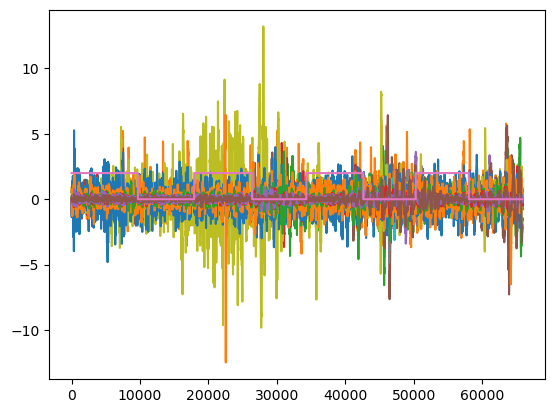

[0 0 0 ... 1 1 1]


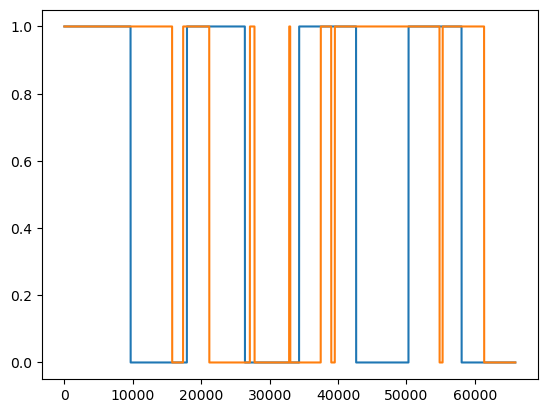

None Training set size: 4392


/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 10 worker processes in total. Our suggested max number of worker in current system is 8 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 10 worker processes in total. Our suggested max number of worker in current system is 8 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.

Batch 0(Minibatch 0): MSE loss:7.90


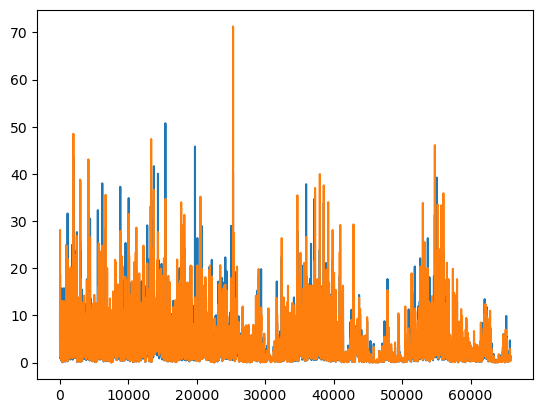

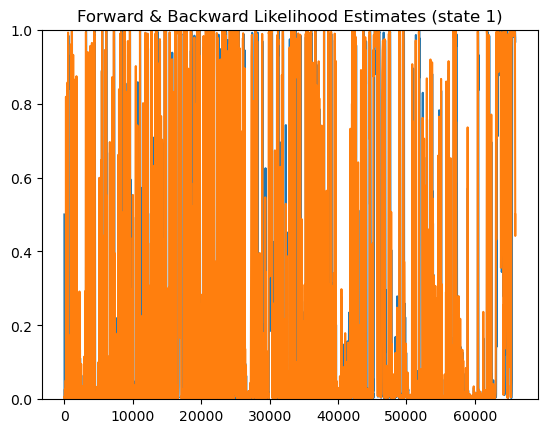

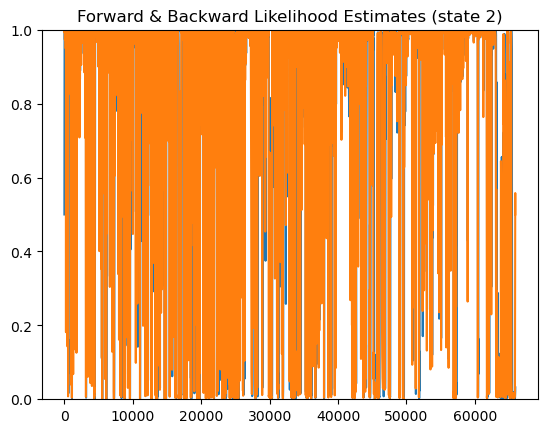

{'pi': tensor([0.4951, 0.5049]), 'A': tensor([[0.9990, 0.0010],
        [0.0011, 0.9989]])}


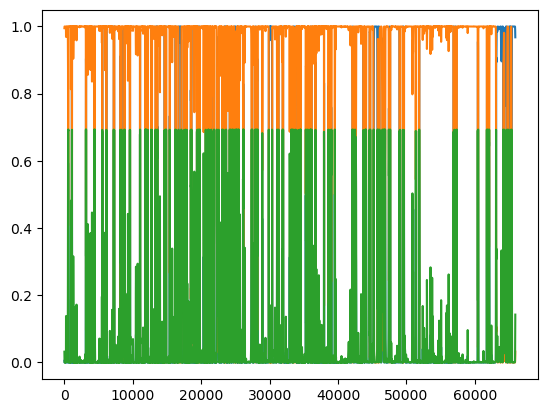

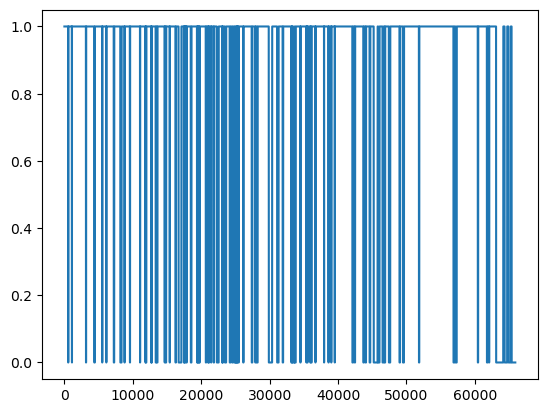

tensor(0.0734)
tensor(0.0012)
tensor([0.3309, 0.3309])
Batch 1(Minibatch 17): MSE loss:1.79
Batch 2(Minibatch 34): MSE loss:0.54
Batch 3(Minibatch 51): MSE loss:0.29
Batch 4(Minibatch 68): MSE loss:0.21
Batch 5(Minibatch 85): MSE loss:0.17
Batch 6(Minibatch 102): MSE loss:0.10
Batch 7(Minibatch 119): MSE loss:0.09
Batch 8(Minibatch 136): MSE loss:0.05
Batch 9(Minibatch 153): MSE loss:0.04
Batch 10(Minibatch 170): MSE loss:0.04
Batch 11(Minibatch 187): MSE loss:0.03
Batch 12(Minibatch 204): MSE loss:0.03
Batch 13(Minibatch 221): MSE loss:0.04
Batch 14(Minibatch 238): MSE loss:0.03
Batch 15(Minibatch 255): MSE loss:0.03
Batch 16(Minibatch 272): MSE loss:0.02
Batch 17(Minibatch 289): MSE loss:0.03
Batch 18(Minibatch 306): MSE loss:0.02
Batch 19(Minibatch 323): MSE loss:0.02
Batch 20(Minibatch 340): MSE loss:0.02
Batch 21(Minibatch 357): MSE loss:0.02
Batch 22(Minibatch 374): MSE loss:0.02
Batch 23(Minibatch 391): MSE loss:0.02
Batch 24(Minibatch 408): MSE loss:0.02
	Unaligned State Accura

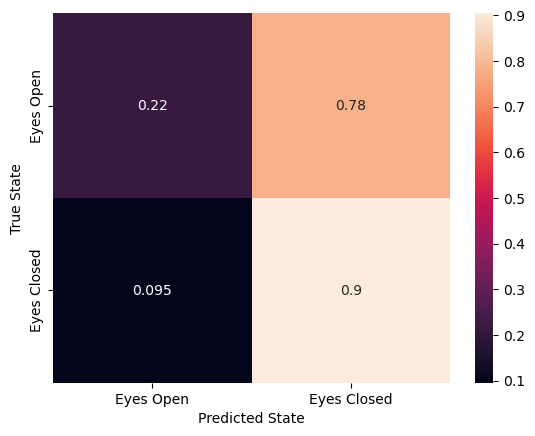

Model Number: 0
	Final Loss: 0.0203629732131958
	State Accuracy: 0.5745000455193761
	Alternate State Accuracy: 0.5612268229030336
	Random State Accuracy: 0.5786726549934755
	Kmeans State Accuracy: 0.5052650745000455
(138795,)


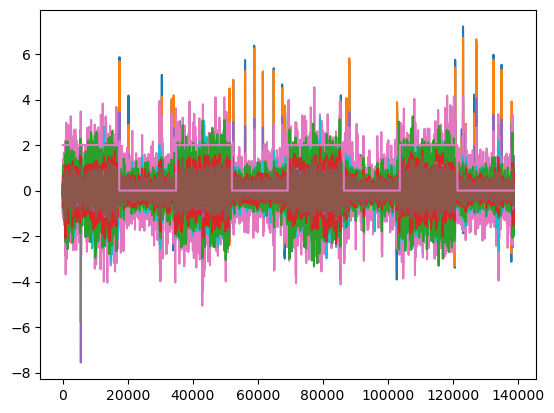

[1 1 1 ... 1 1 1]


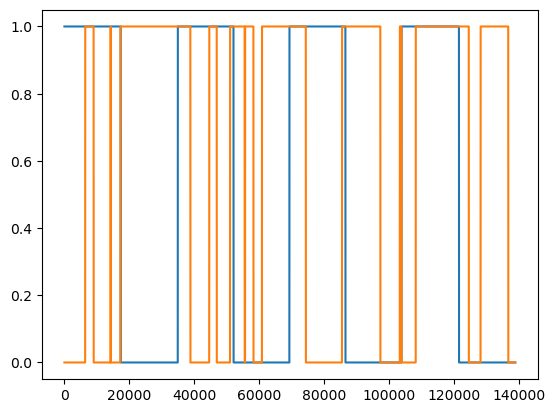

None Training set size: 9251


/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 10 worker processes in total. Our suggested max number of worker in current system is 8 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 10 worker processes in total. Our suggested max number of worker in current system is 8 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.

Batch 0(Minibatch 0): MSE loss:3.56


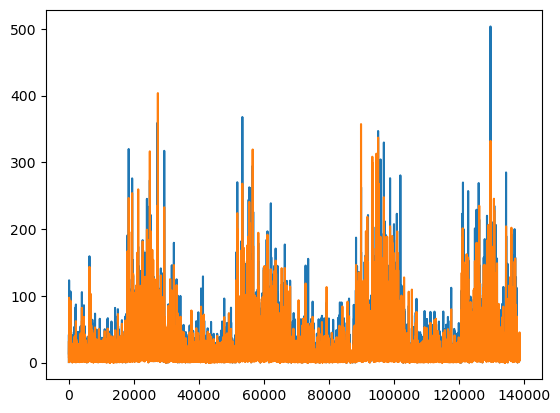

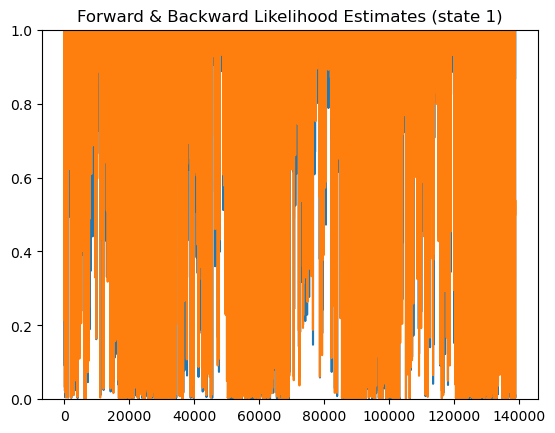

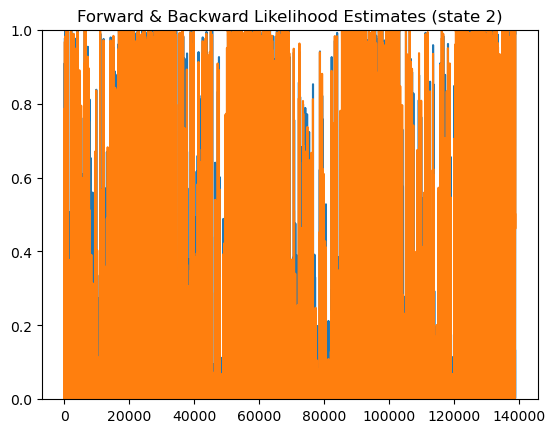

{'pi': tensor([0.5049, 0.4951]), 'A': tensor([[0.9989, 0.0011],
        [0.0010, 0.9990]])}


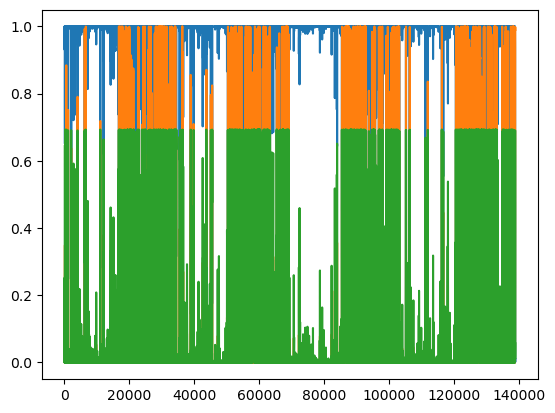

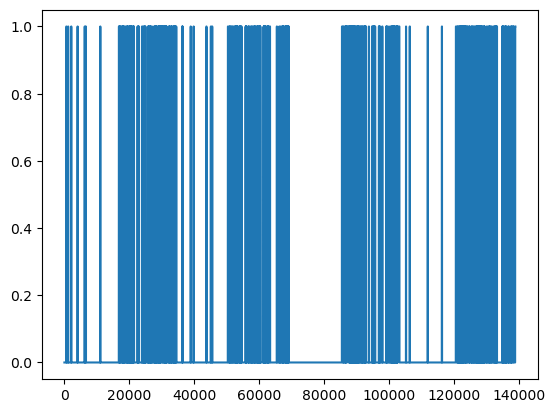

tensor(0.0764)
tensor(0.0019)
tensor([0.3055, 0.3055])
Batch 1(Minibatch 37): MSE loss:0.39
Batch 2(Minibatch 74): MSE loss:0.05
Batch 3(Minibatch 111): MSE loss:0.03
Batch 4(Minibatch 148): MSE loss:0.02
Batch 5(Minibatch 185): MSE loss:0.02
Batch 6(Minibatch 222): MSE loss:0.02
Batch 7(Minibatch 259): MSE loss:0.02
Batch 8(Minibatch 296): MSE loss:0.01
Batch 9(Minibatch 333): MSE loss:0.02
Batch 10(Minibatch 370): MSE loss:0.02
Batch 11(Minibatch 407): MSE loss:0.02
Batch 12(Minibatch 444): MSE loss:0.01
Batch 13(Minibatch 481): MSE loss:0.01
Batch 14(Minibatch 518): MSE loss:0.01
Batch 15(Minibatch 555): MSE loss:0.01
Batch 16(Minibatch 592): MSE loss:0.01
Batch 17(Minibatch 629): MSE loss:0.01
Batch 18(Minibatch 666): MSE loss:0.01
Batch 19(Minibatch 703): MSE loss:0.01
Batch 20(Minibatch 740): MSE loss:0.01
Batch 21(Minibatch 777): MSE loss:0.01
Batch 22(Minibatch 814): MSE loss:0.01
Batch 23(Minibatch 851): MSE loss:0.01
Batch 24(Minibatch 888): MSE loss:0.01
	Unaligned State Acc

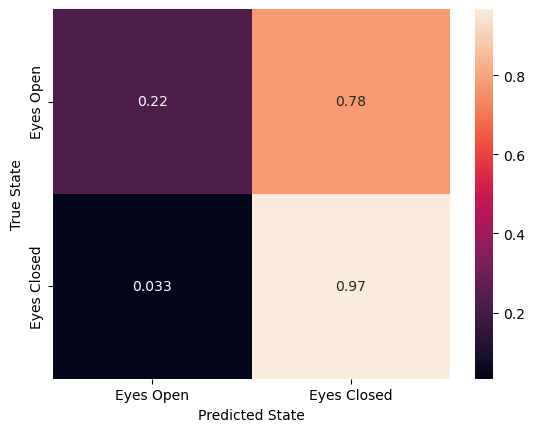

Model Number: 1
	Final Loss: 0.010872662998735905
	State Accuracy: 0.5962750819554018
	Alternate State Accuracy: 0.5961439880061639
	Random State Accuracy: 0.6829568788501027
	Kmeans State Accuracy: 0.5117907705608992
(68147,)


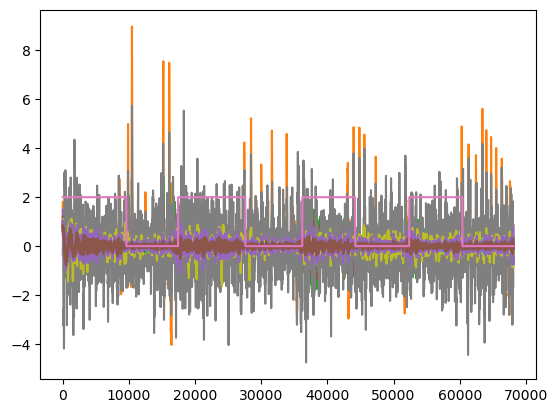

[0 0 0 ... 1 1 1]


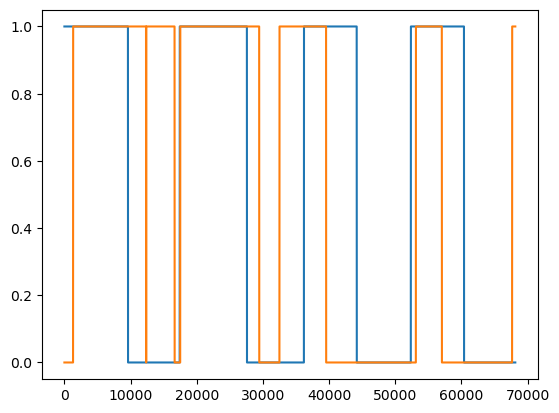

None Training set size: 4541


/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 10 worker processes in total. Our suggested max number of worker in current system is 8 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 10 worker processes in total. Our suggested max number of worker in current system is 8 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.

Batch 0(Minibatch 0): MSE loss:2.11


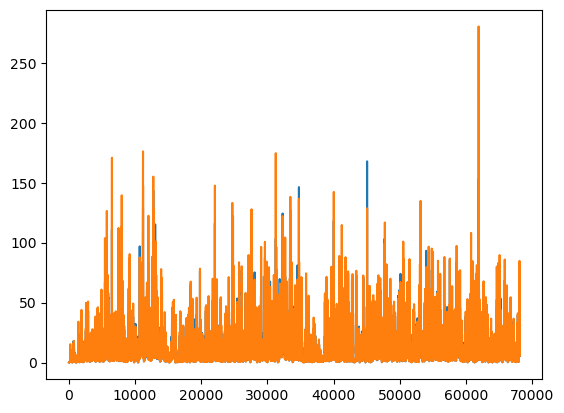

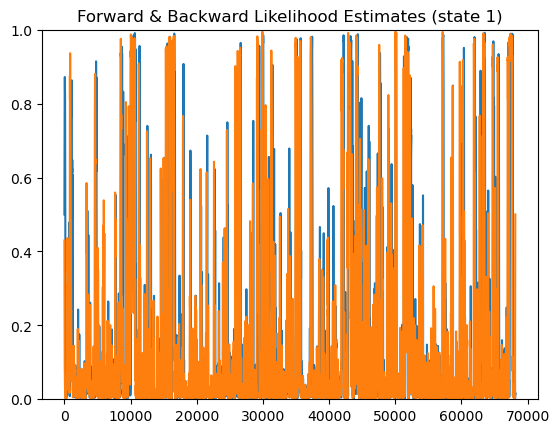

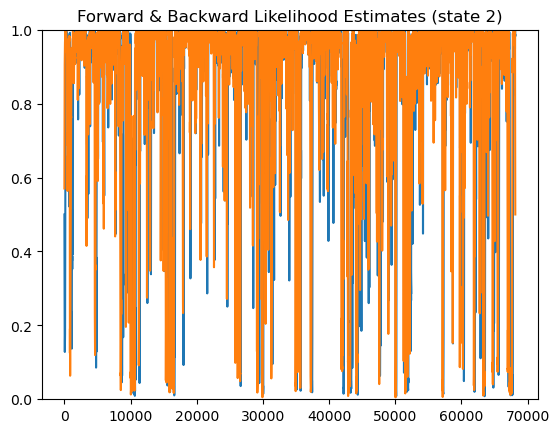

{'pi': tensor([0.4993, 0.5007]), 'A': tensor([[9.9901e-01, 9.9477e-04],
        [1.0389e-03, 9.9896e-01]])}


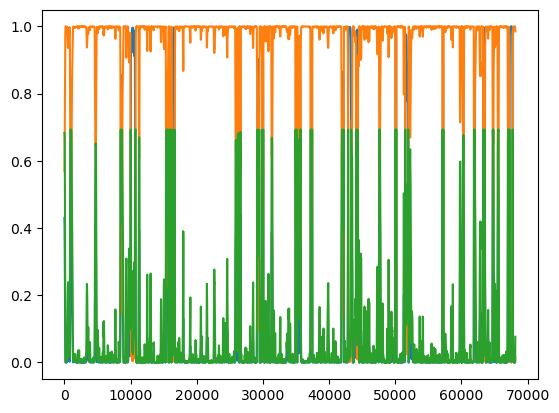

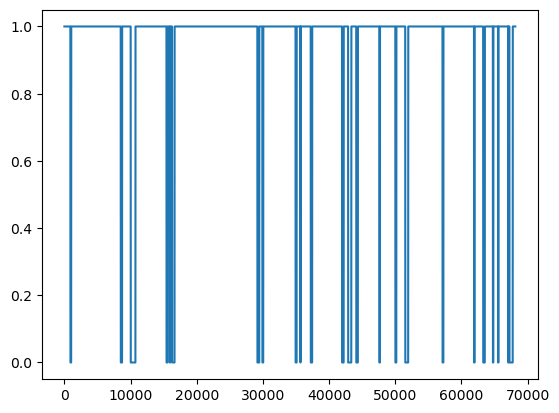

tensor(0.0911)
tensor(0.0101)
tensor([0.2365, 0.2365])
Batch 1(Minibatch 18): MSE loss:0.48


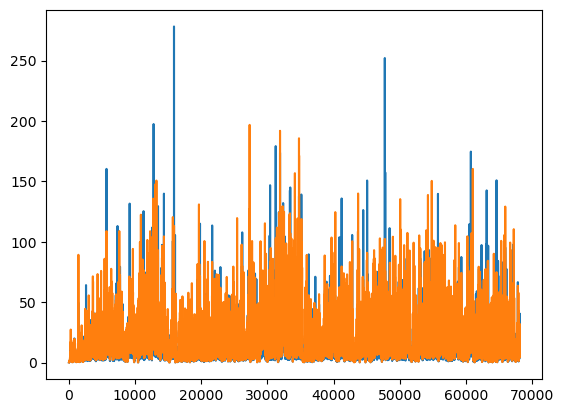

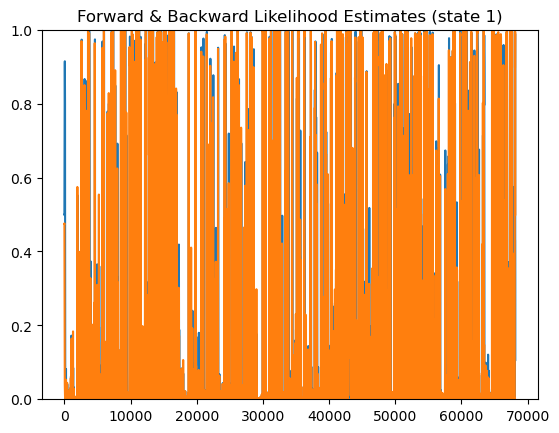

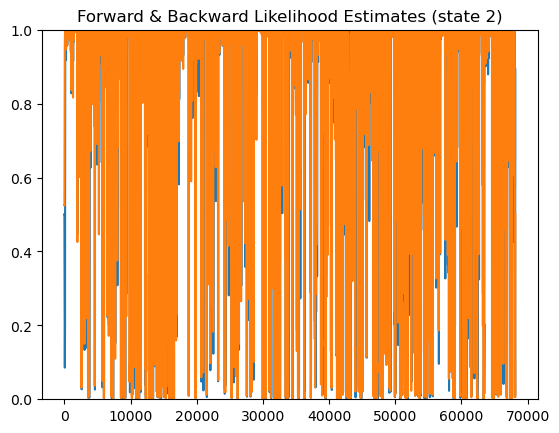

{'pi': tensor([0.4990, 0.5010]), 'A': tensor([[0.9990, 0.0010],
        [0.0012, 0.9988]])}


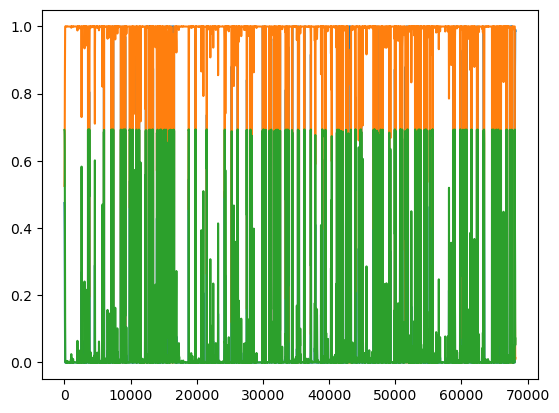

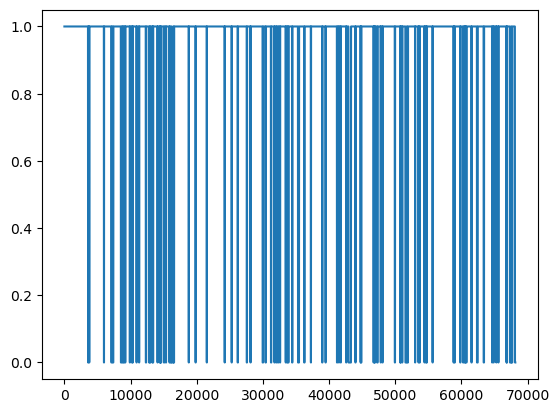

tensor(0.0571)
tensor(0.0002)
tensor([0.2464, 0.2464])
Batch 2(Minibatch 36): MSE loss:0.21


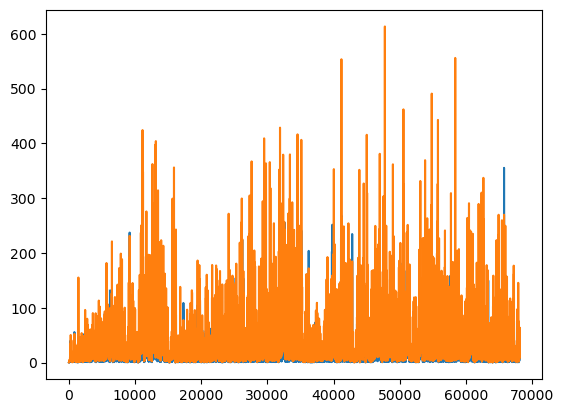

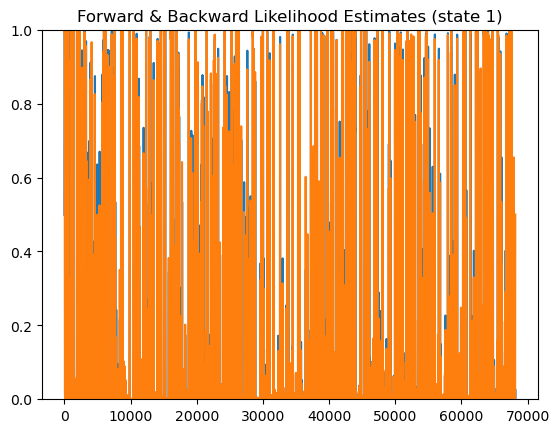

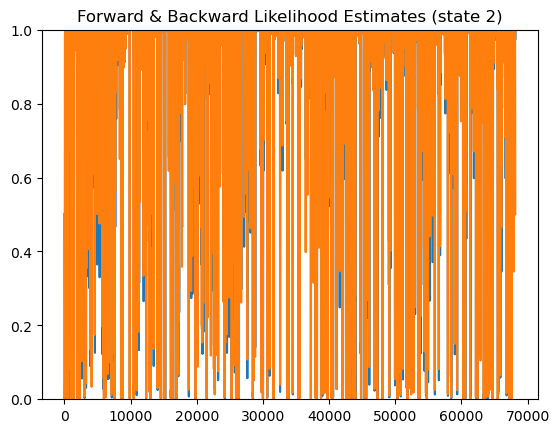

{'pi': tensor([0.5040, 0.4960]), 'A': tensor([[0.9990, 0.0010],
        [0.0014, 0.9986]])}


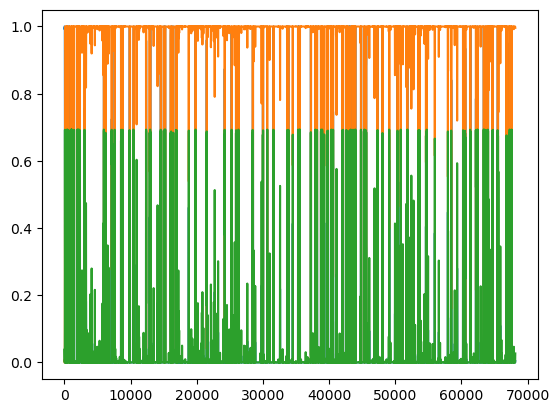

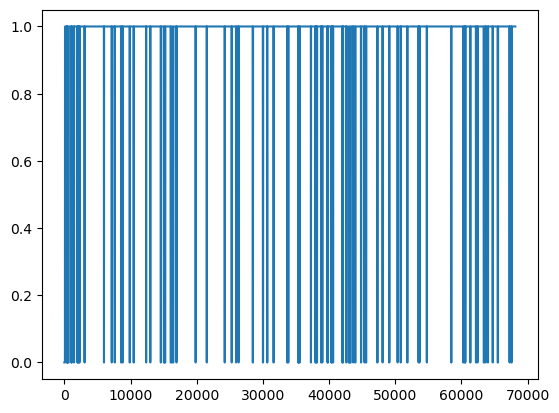

tensor(0.0287)
tensor(2.4379e-05)
tensor([0.2061, 0.2061])
Batch 3(Minibatch 54): MSE loss:0.12


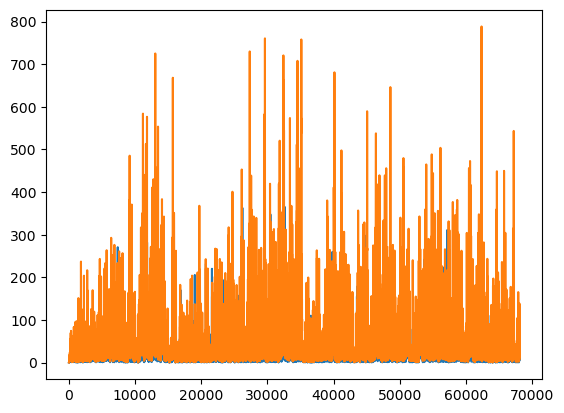

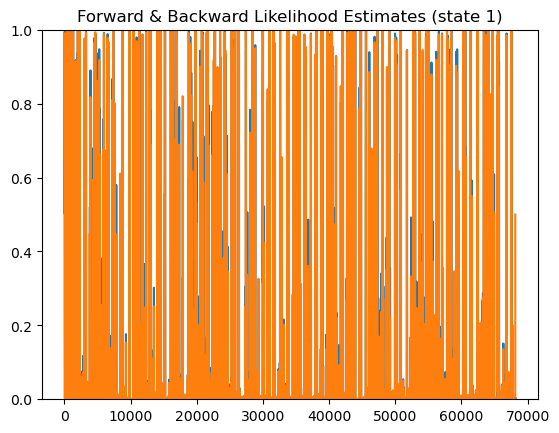

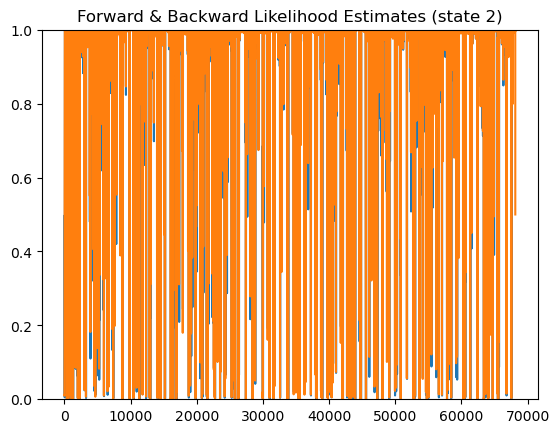

{'pi': tensor([0.5088, 0.4912]), 'A': tensor([[0.9990, 0.0010],
        [0.0015, 0.9985]])}


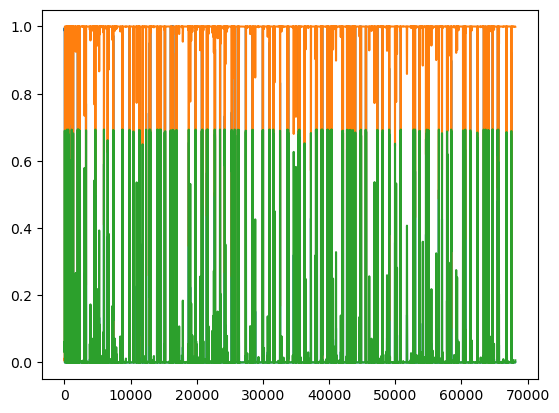

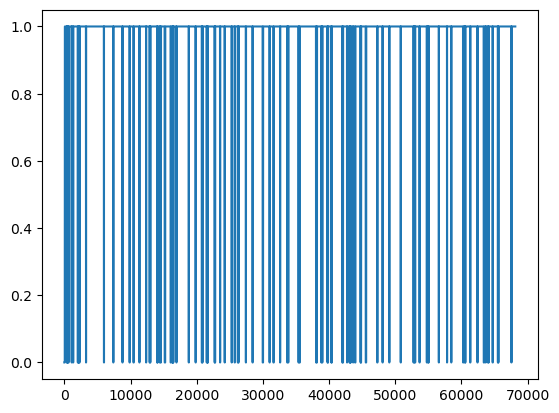

tensor(0.0264)
tensor(2.0019e-05)
tensor([0.1842, 0.1842])
Batch 4(Minibatch 72): MSE loss:0.10


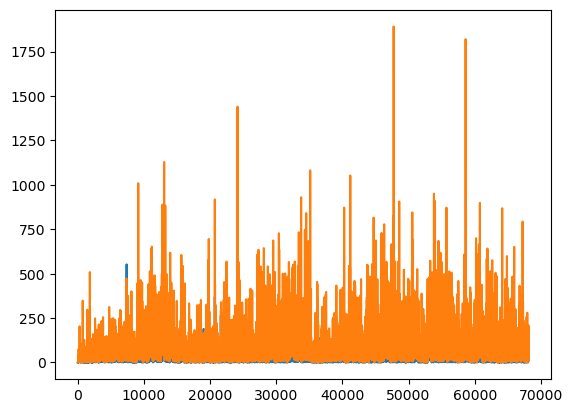

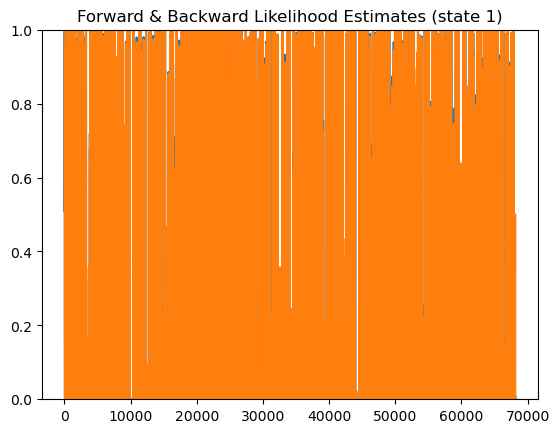

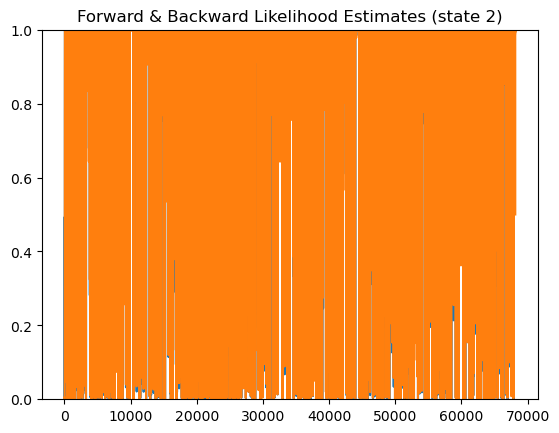

{'pi': tensor([0.5137, 0.4863]), 'A': tensor([[0.9989, 0.0011],
        [0.0018, 0.9982]])}


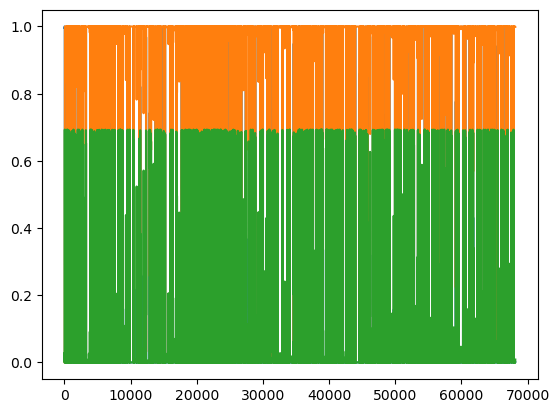

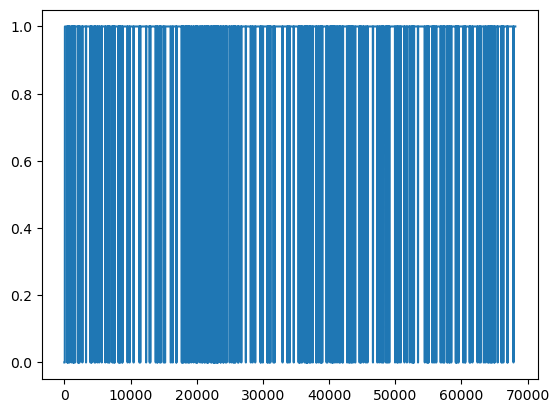

tensor(0.0521)
tensor(2.0090e-05)
tensor([0.2422, 0.2422])
Batch 5(Minibatch 90): MSE loss:0.07


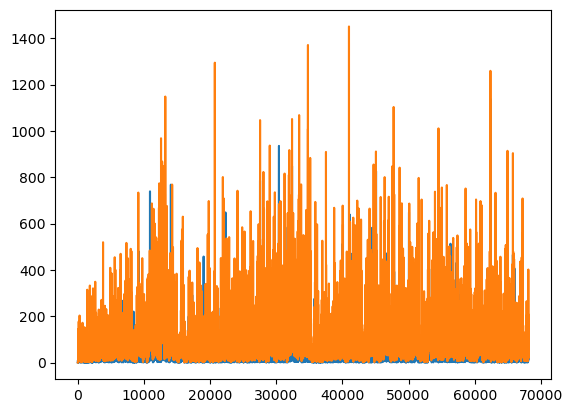

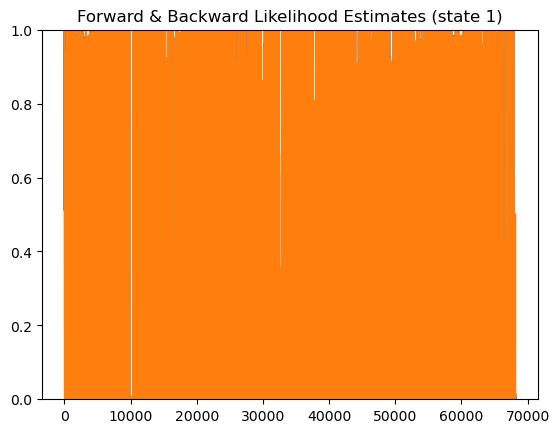

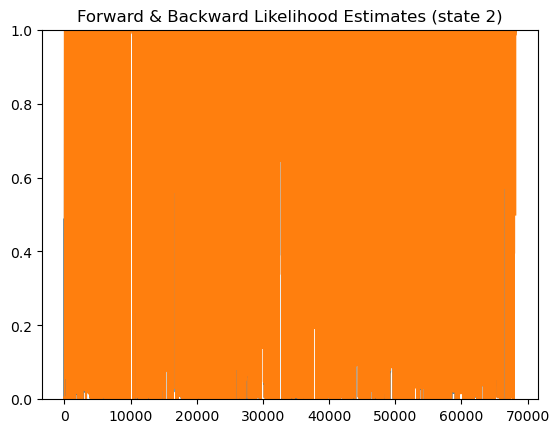

{'pi': tensor([0.5185, 0.4815]), 'A': tensor([[0.9989, 0.0011],
        [0.0020, 0.9980]])}


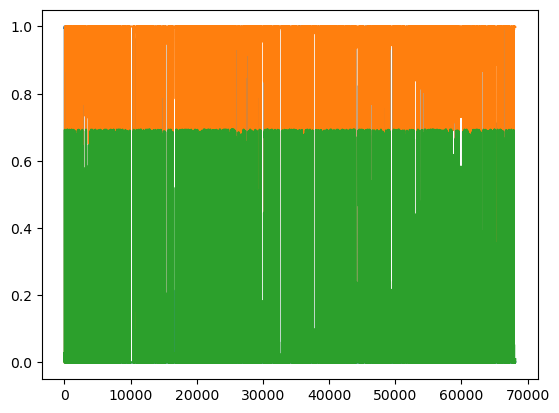

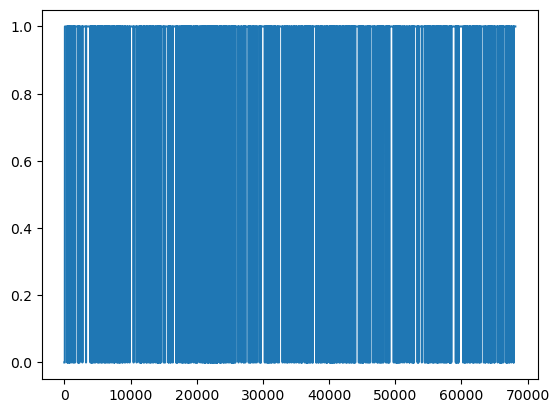

tensor(0.0657)
tensor(2.6683e-05)
tensor([0.2900, 0.2900])
Batch 6(Minibatch 108): MSE loss:0.05
Batch 7(Minibatch 126): MSE loss:0.05
Batch 8(Minibatch 144): MSE loss:0.03
Batch 9(Minibatch 162): MSE loss:0.02
Batch 10(Minibatch 180): MSE loss:0.01
Batch 11(Minibatch 198): MSE loss:0.02
Batch 12(Minibatch 216): MSE loss:0.02
Batch 13(Minibatch 234): MSE loss:0.01
Batch 14(Minibatch 252): MSE loss:0.01
Batch 15(Minibatch 270): MSE loss:0.01
Batch 16(Minibatch 288): MSE loss:0.02
Batch 17(Minibatch 306): MSE loss:0.01
Batch 18(Minibatch 324): MSE loss:0.01
Batch 19(Minibatch 342): MSE loss:0.01
Batch 20(Minibatch 360): MSE loss:0.01
Batch 21(Minibatch 378): MSE loss:0.01
Batch 22(Minibatch 396): MSE loss:0.01
Batch 23(Minibatch 414): MSE loss:0.01
Batch 24(Minibatch 432): MSE loss:0.01
	Unaligned State Accuracy: 0.5157820593716524
[[0.11031479 0.88968521]
 [0.11734123 0.88265877]]
	Hungarian matches (true state, fit state): [(0, 0), (1, 1)]
[[0.11031479 0.88968521]
 [0.11734123 0.882658

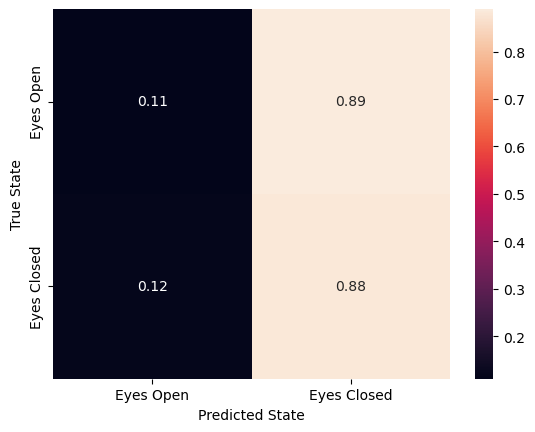

Model Number: 2
	Final Loss: 0.008625580929219723
	State Accuracy: 0.5157820593716524
	Alternate State Accuracy: 0.4964867767902088
	Random State Accuracy: 0.659794268272998
	Kmeans State Accuracy: 0.528167050640527
(64123,)


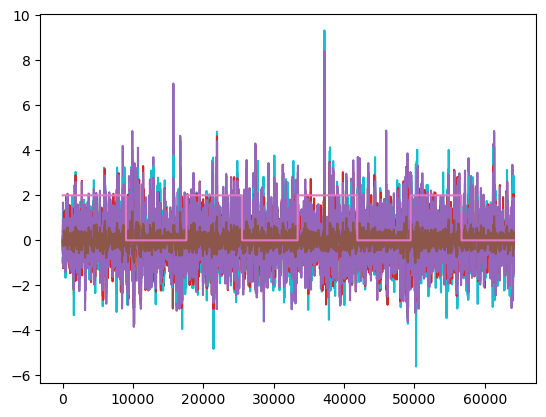

[0 0 0 ... 0 0 0]


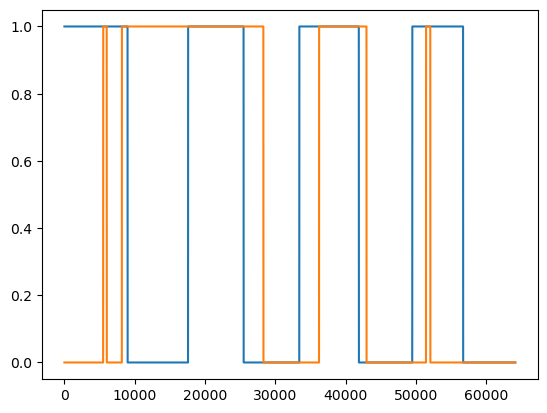

None Training set size: 4273


/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 10 worker processes in total. Our suggested max number of worker in current system is 8 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 10 worker processes in total. Our suggested max number of worker in current system is 8 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.

Batch 0(Minibatch 0): MSE loss:3.98


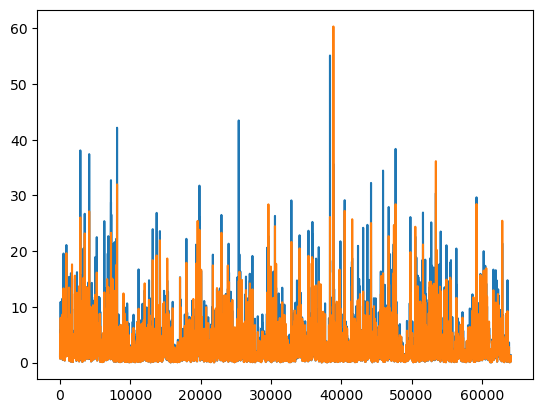

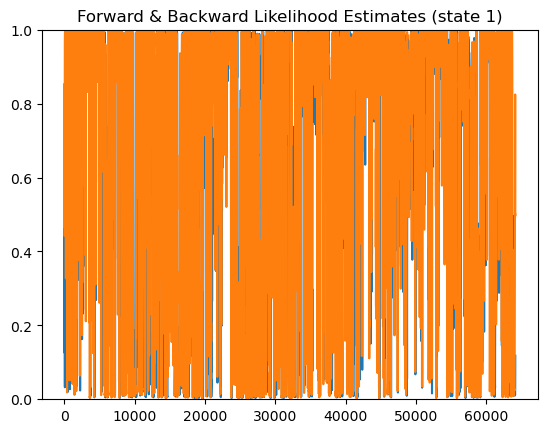

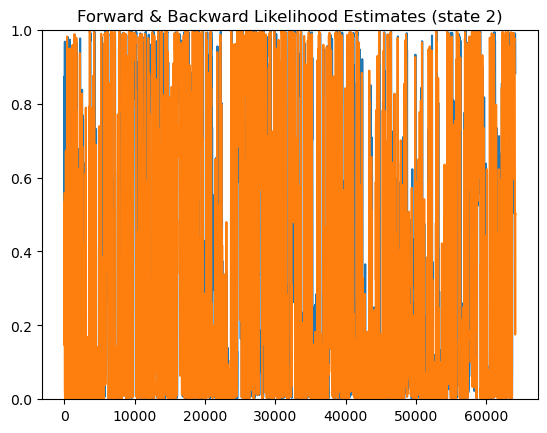

{'pi': tensor([0.4994, 0.5006]), 'A': tensor([[0.9990, 0.0010],
        [0.0010, 0.9990]])}


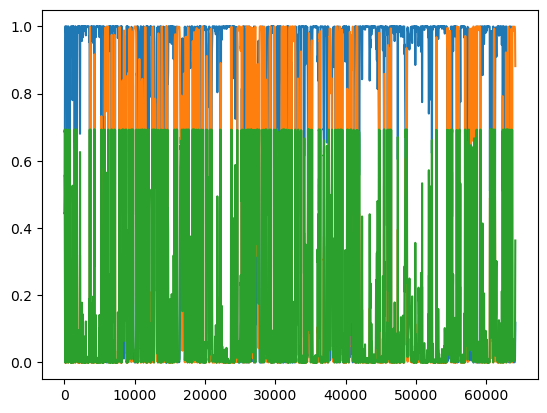

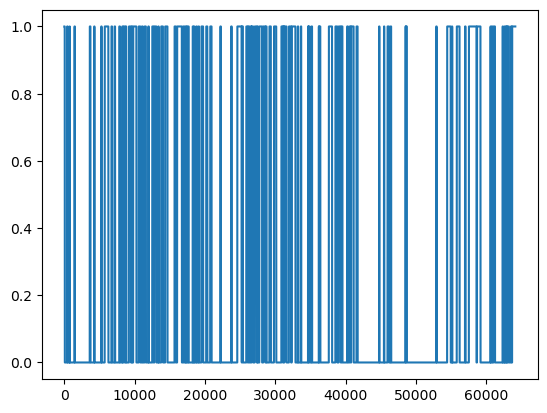

tensor(0.1509)
tensor(0.0310)
tensor([0.3975, 0.3975])
Batch 1(Minibatch 17): MSE loss:1.67


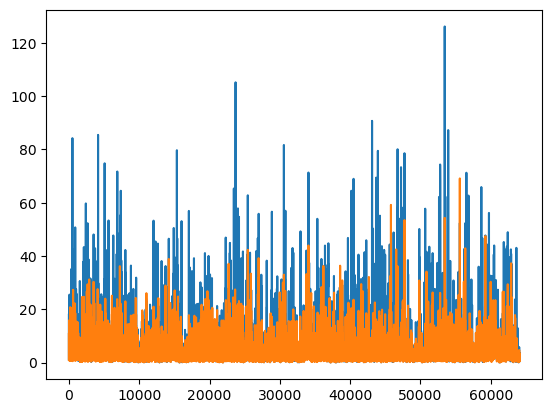

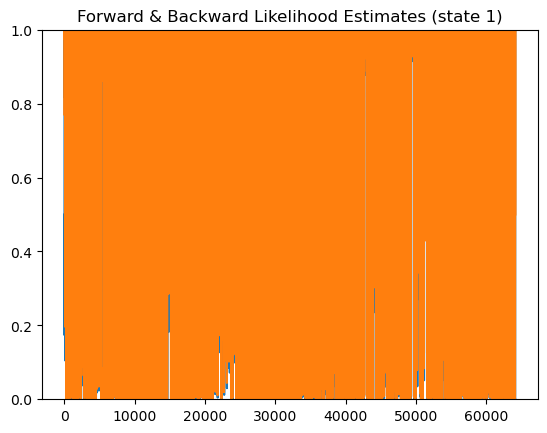

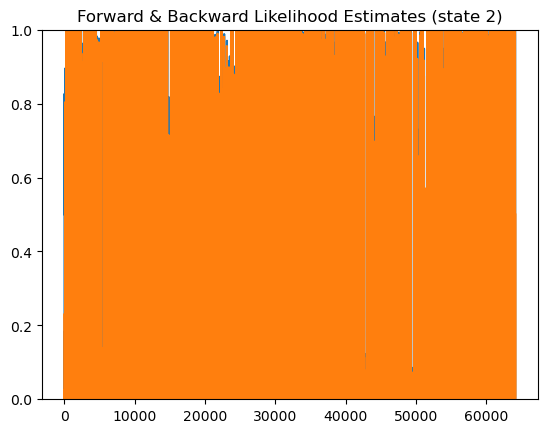

{'pi': tensor([0.5042, 0.4958]), 'A': tensor([[0.9988, 0.0012],
        [0.0011, 0.9989]])}


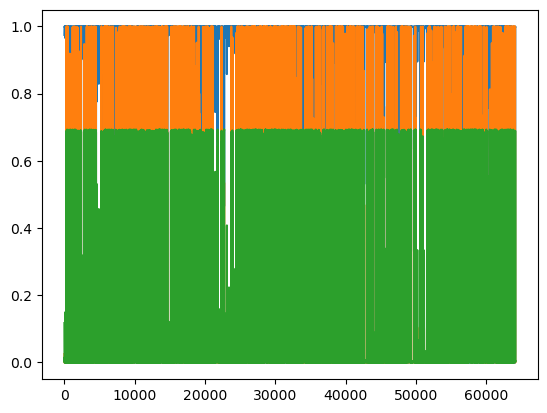

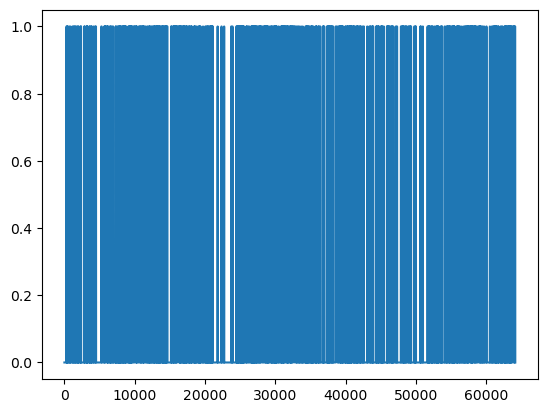

tensor(0.0890)
tensor(0.0007)
tensor([0.4262, 0.4262])
Batch 2(Minibatch 34): MSE loss:0.90
Batch 3(Minibatch 51): MSE loss:0.45
Batch 4(Minibatch 68): MSE loss:0.24
Batch 5(Minibatch 85): MSE loss:0.15
Batch 6(Minibatch 102): MSE loss:0.11
Batch 7(Minibatch 119): MSE loss:0.05
Batch 8(Minibatch 136): MSE loss:0.04
Batch 9(Minibatch 153): MSE loss:0.05
Batch 10(Minibatch 170): MSE loss:0.04
Batch 11(Minibatch 187): MSE loss:0.03
Batch 12(Minibatch 204): MSE loss:0.03
Batch 13(Minibatch 221): MSE loss:0.03
Batch 14(Minibatch 238): MSE loss:0.03
Batch 15(Minibatch 255): MSE loss:0.03
Batch 16(Minibatch 272): MSE loss:0.02
Batch 17(Minibatch 289): MSE loss:0.02
Batch 18(Minibatch 306): MSE loss:0.02
Batch 19(Minibatch 323): MSE loss:0.02
Batch 20(Minibatch 340): MSE loss:0.02
Batch 21(Minibatch 357): MSE loss:0.02
Batch 22(Minibatch 374): MSE loss:0.01
Batch 23(Minibatch 391): MSE loss:0.02
Batch 24(Minibatch 408): MSE loss:0.02
	Unaligned State Accuracy: 0.4185549646772609
[[0.62708802 0

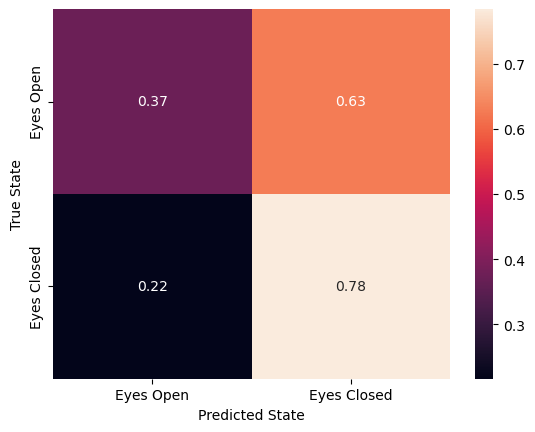

Model Number: 3
	Final Loss: 0.019637178629636765
	State Accuracy: 0.5814450353227391
	Alternate State Accuracy: 0.5781640998595117
	Random State Accuracy: 0.5384963273708342
	Kmeans State Accuracy: 0.5048110662320852
(61958,)


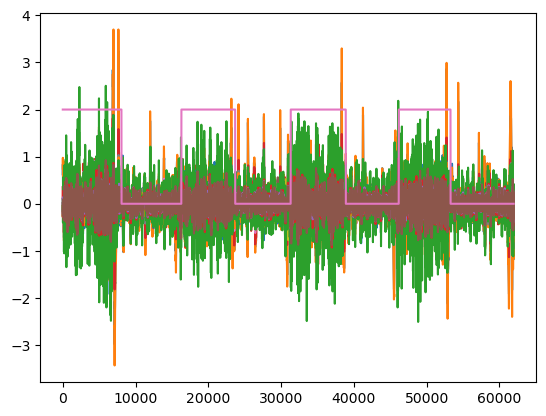

[1 1 1 ... 0 0 0]


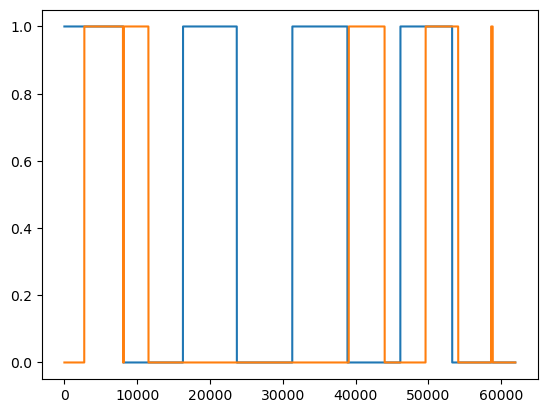

None Training set size: 4129


/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 10 worker processes in total. Our suggested max number of worker in current system is 8 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 10 worker processes in total. Our suggested max number of worker in current system is 8 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.

Batch 0(Minibatch 0): MSE loss:1.18


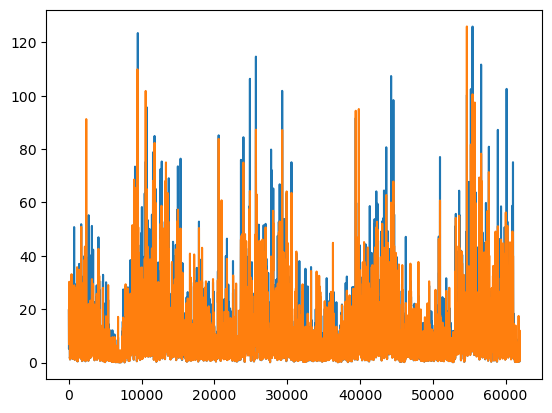

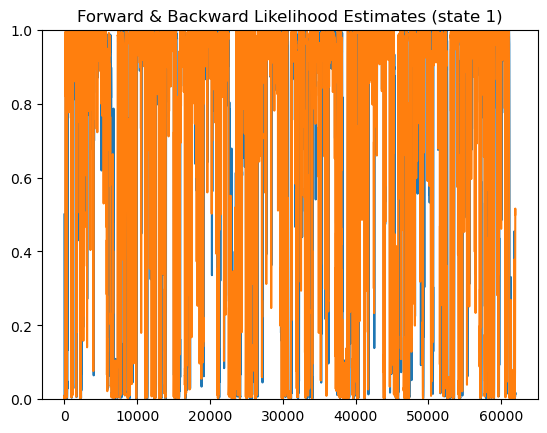

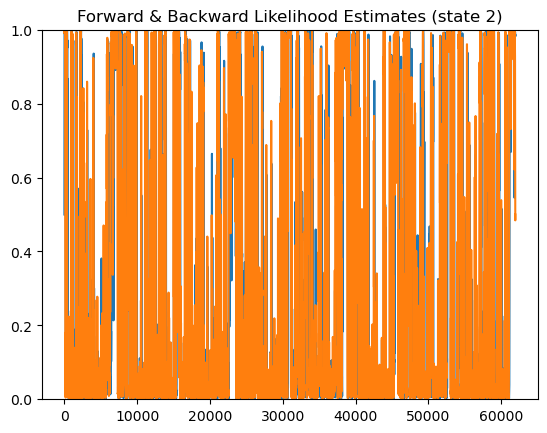

{'pi': tensor([0.4950, 0.5050]), 'A': tensor([[0.9990, 0.0010],
        [0.0010, 0.9990]])}


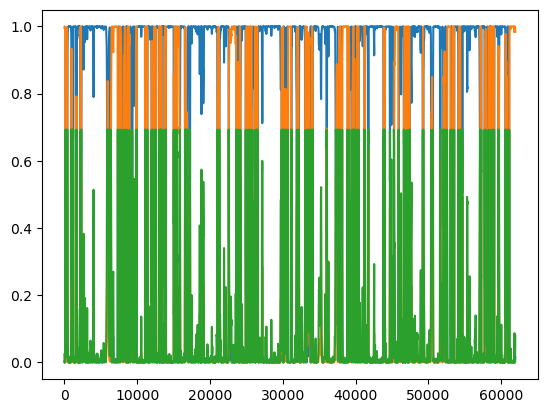

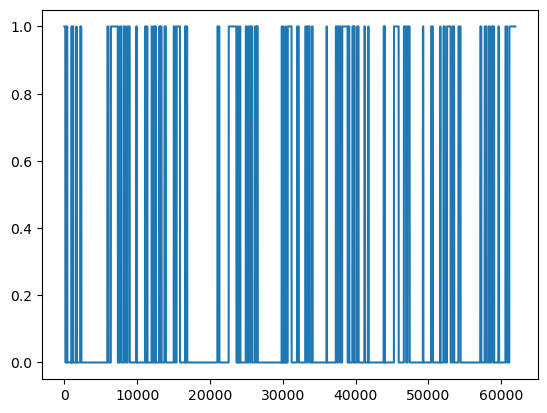

tensor(0.1064)
tensor(0.0105)
tensor([0.3923, 0.3923])
Batch 1(Minibatch 16): MSE loss:0.45
Batch 2(Minibatch 32): MSE loss:0.27
Batch 3(Minibatch 48): MSE loss:0.19
Batch 4(Minibatch 64): MSE loss:0.12
Batch 5(Minibatch 80): MSE loss:0.09
Batch 6(Minibatch 96): MSE loss:0.05
Batch 7(Minibatch 112): MSE loss:0.04
Batch 8(Minibatch 128): MSE loss:0.02
Batch 9(Minibatch 144): MSE loss:0.02
Batch 10(Minibatch 160): MSE loss:0.01
Batch 11(Minibatch 176): MSE loss:0.01
Batch 12(Minibatch 192): MSE loss:0.01
Batch 13(Minibatch 208): MSE loss:0.02
Batch 14(Minibatch 224): MSE loss:0.01
Batch 15(Minibatch 240): MSE loss:0.01
Batch 16(Minibatch 256): MSE loss:0.01
Batch 17(Minibatch 272): MSE loss:0.01
Batch 18(Minibatch 288): MSE loss:0.01
Batch 19(Minibatch 304): MSE loss:0.01
Batch 20(Minibatch 320): MSE loss:0.01
Batch 21(Minibatch 336): MSE loss:0.01
Batch 22(Minibatch 352): MSE loss:0.01
Batch 23(Minibatch 368): MSE loss:0.01
Batch 24(Minibatch 384): MSE loss:0.01
	Unaligned State Accurac

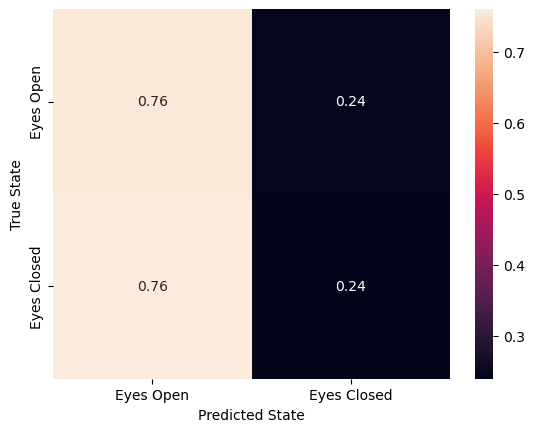

Model Number: 4
	Final Loss: 0.00793367251753807
	State Accuracy: 0.5046967300429324
	Alternate State Accuracy: 0.49774377998873276
	Random State Accuracy: 0.5072307046709061
	Kmeans State Accuracy: 0.5006133186997643
(57704,)


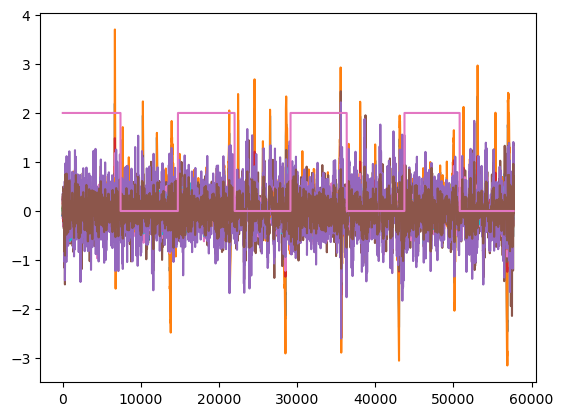

[1 1 1 ... 1 1 1]


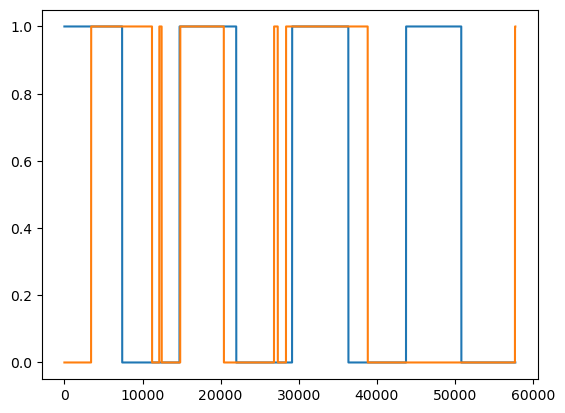

None Training set size: 3845


/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 10 worker processes in total. Our suggested max number of worker in current system is 8 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 10 worker processes in total. Our suggested max number of worker in current system is 8 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.

Batch 0(Minibatch 0): MSE loss:1.05


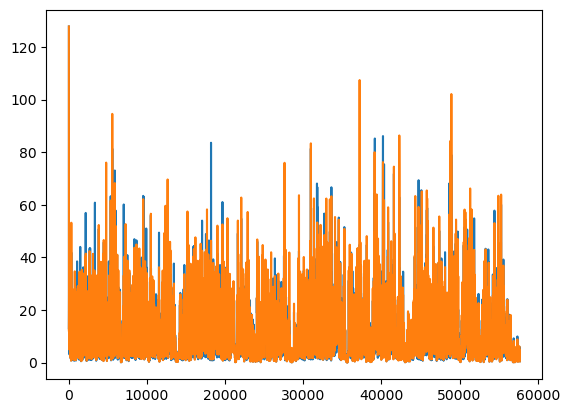

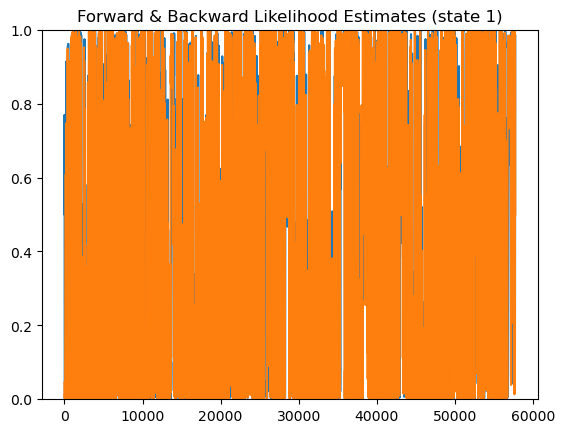

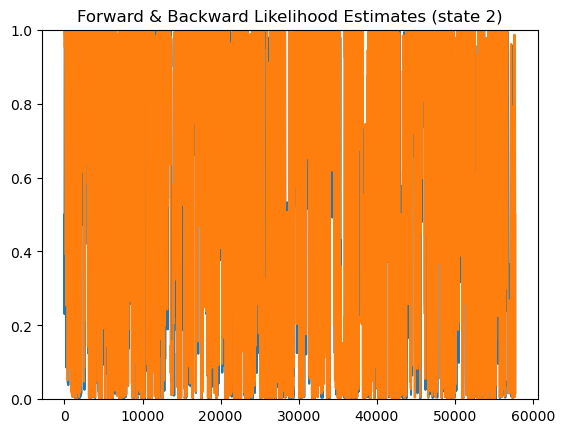

{'pi': tensor([0.4955, 0.5045]), 'A': tensor([[0.9990, 0.0010],
        [0.0011, 0.9989]])}


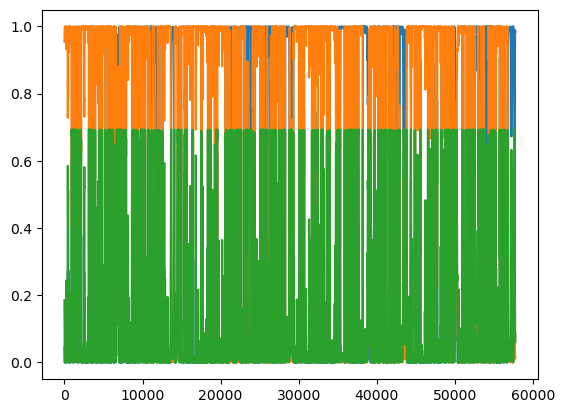

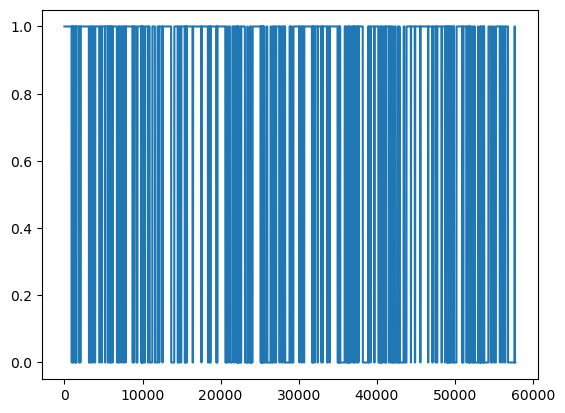

tensor(0.1453)
tensor(0.0237)
tensor([0.4173, 0.4173])
Batch 1(Minibatch 15): MSE loss:0.28
Batch 2(Minibatch 30): MSE loss:0.22
Batch 3(Minibatch 45): MSE loss:0.19
Batch 4(Minibatch 60): MSE loss:0.12
Batch 5(Minibatch 75): MSE loss:0.13
Batch 6(Minibatch 90): MSE loss:0.07
Batch 7(Minibatch 105): MSE loss:0.06
Batch 8(Minibatch 120): MSE loss:0.06
Batch 9(Minibatch 135): MSE loss:0.03
Batch 10(Minibatch 150): MSE loss:0.03
Batch 11(Minibatch 165): MSE loss:0.03
Batch 12(Minibatch 180): MSE loss:0.02
Batch 13(Minibatch 195): MSE loss:0.02
Batch 14(Minibatch 210): MSE loss:0.02
Batch 15(Minibatch 225): MSE loss:0.01
Batch 16(Minibatch 240): MSE loss:0.01
Batch 17(Minibatch 255): MSE loss:0.01
Batch 18(Minibatch 270): MSE loss:0.01
Batch 19(Minibatch 285): MSE loss:0.01
Batch 20(Minibatch 300): MSE loss:0.01
Batch 21(Minibatch 315): MSE loss:0.01
Batch 22(Minibatch 330): MSE loss:0.01
Batch 23(Minibatch 345): MSE loss:0.01
Batch 24(Minibatch 360): MSE loss:0.01
	Unaligned State Accurac

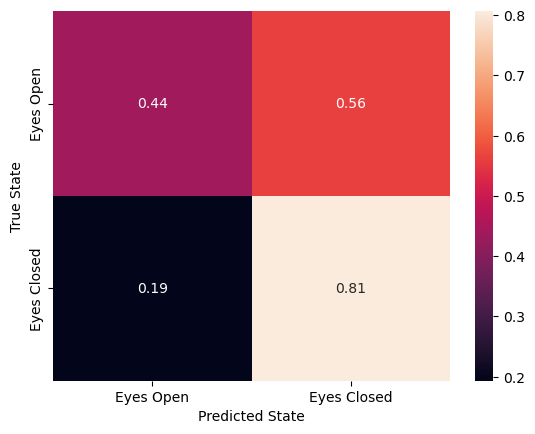

Model Number: 5
	Final Loss: 0.007379626855254173
	State Accuracy: 0.6231976985997505
	Alternate State Accuracy: 0.6228090641731852
	Random State Accuracy: 0.652155829751837
	Kmeans State Accuracy: 0.5092887841397477
(43372,)


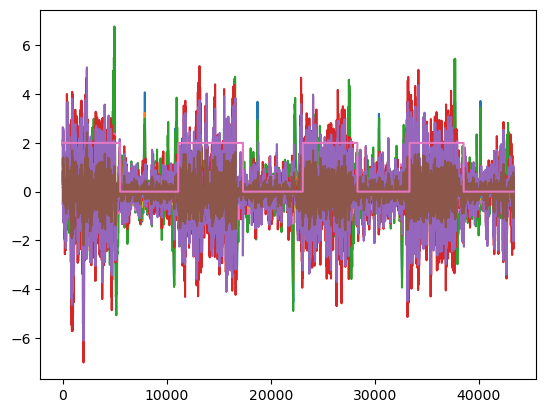

[1 1 1 ... 1 1 1]


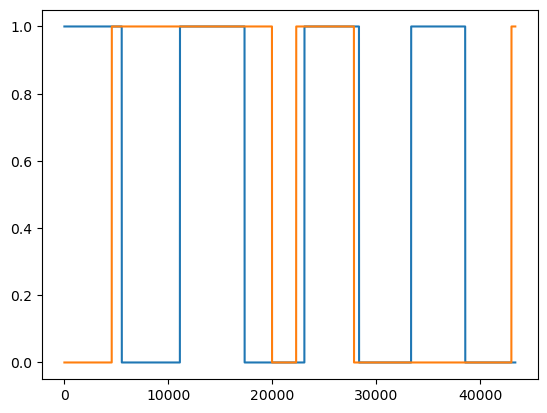

None Training set size: 2890


/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 10 worker processes in total. Our suggested max number of worker in current system is 8 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 10 worker processes in total. Our suggested max number of worker in current system is 8 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.

Batch 0(Minibatch 0): MSE loss:4.95


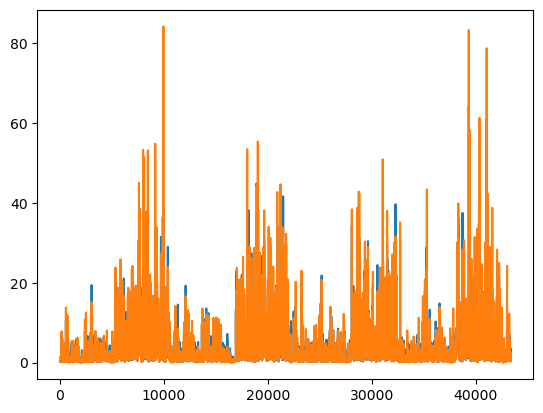

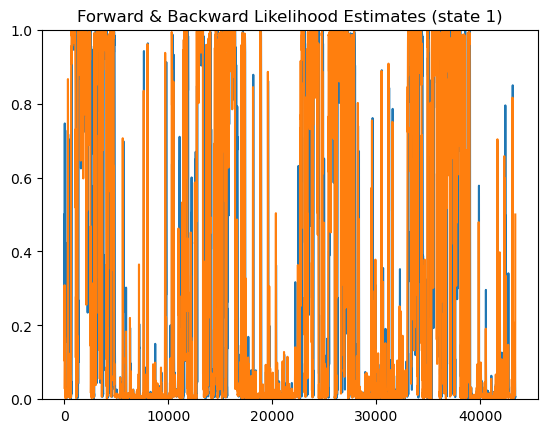

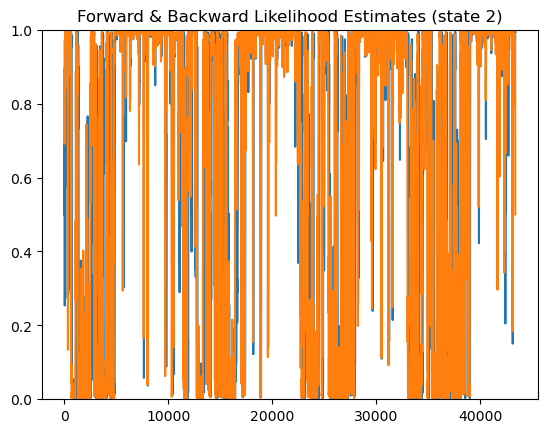

{'pi': tensor([0.4961, 0.5039]), 'A': tensor([[0.9990, 0.0010],
        [0.0010, 0.9990]])}


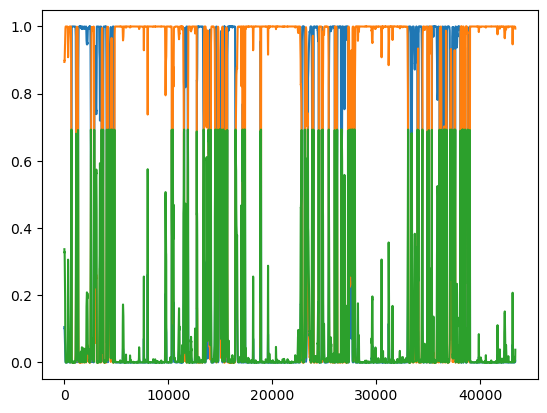

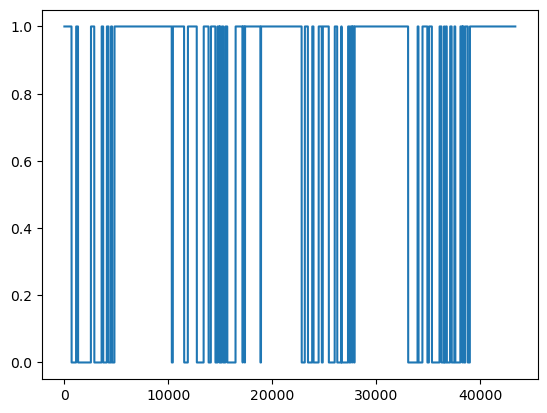

tensor(0.0883)
tensor(0.0030)
tensor([0.4290, 0.4290])
Batch 1(Minibatch 11): MSE loss:1.93
Batch 2(Minibatch 22): MSE loss:1.39
Batch 3(Minibatch 33): MSE loss:1.19
Batch 4(Minibatch 44): MSE loss:0.72
Batch 5(Minibatch 55): MSE loss:0.51
Batch 6(Minibatch 66): MSE loss:0.28
Batch 7(Minibatch 77): MSE loss:0.18
Batch 8(Minibatch 88): MSE loss:0.08
Batch 9(Minibatch 99): MSE loss:0.05
Batch 10(Minibatch 110): MSE loss:0.05
Batch 11(Minibatch 121): MSE loss:0.04
Batch 12(Minibatch 132): MSE loss:0.04
Batch 13(Minibatch 143): MSE loss:0.04
Batch 14(Minibatch 154): MSE loss:0.03
Batch 15(Minibatch 165): MSE loss:0.03
Batch 16(Minibatch 176): MSE loss:0.03
Batch 17(Minibatch 187): MSE loss:0.03
Batch 18(Minibatch 198): MSE loss:0.02
Batch 19(Minibatch 209): MSE loss:0.02
Batch 20(Minibatch 220): MSE loss:0.02
Batch 21(Minibatch 231): MSE loss:0.02
Batch 22(Minibatch 242): MSE loss:0.02
Batch 23(Minibatch 253): MSE loss:0.02
Batch 24(Minibatch 264): MSE loss:0.02
	Unaligned State Accuracy: 

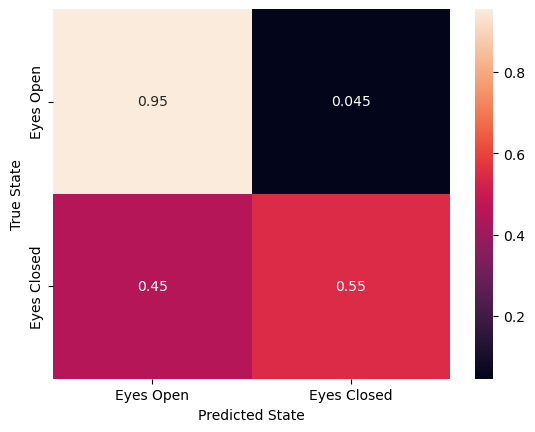

Model Number: 6
	Final Loss: 0.016894809901714325
	State Accuracy: 0.7464493221433183
	Alternate State Accuracy: 0.7511465758004578
	Random State Accuracy: 0.5470580097758923
	Kmeans State Accuracy: 0.5056949183805219
(57011,)


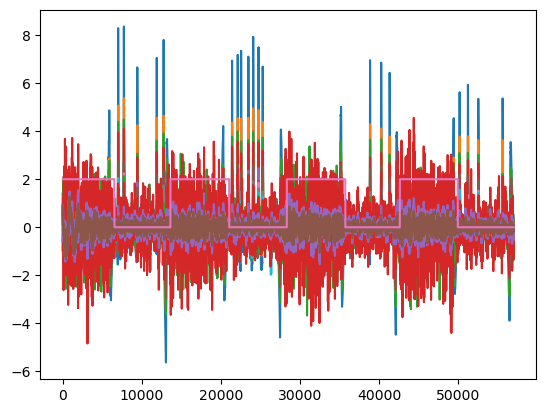

[0 0 0 ... 0 0 0]


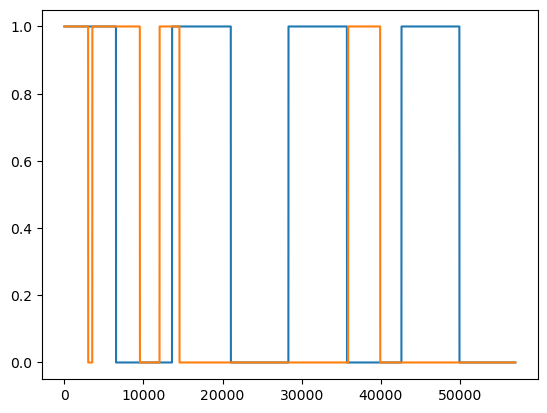

None Training set size: 3799


/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 10 worker processes in total. Our suggested max number of worker in current system is 8 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 10 worker processes in total. Our suggested max number of worker in current system is 8 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.

Batch 0(Minibatch 0): MSE loss:6.04


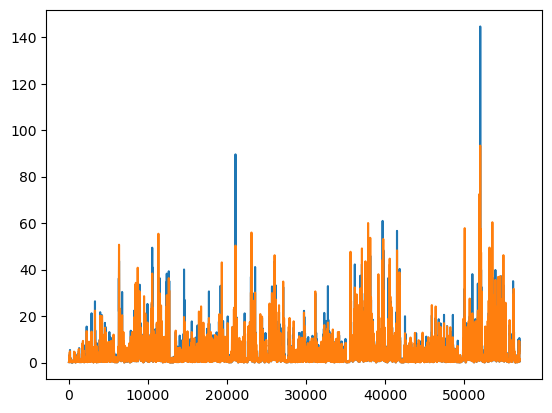

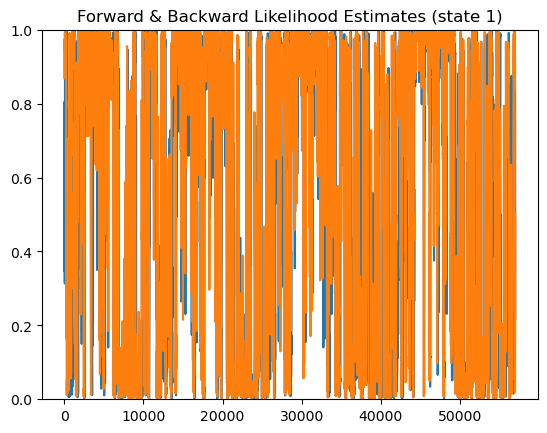

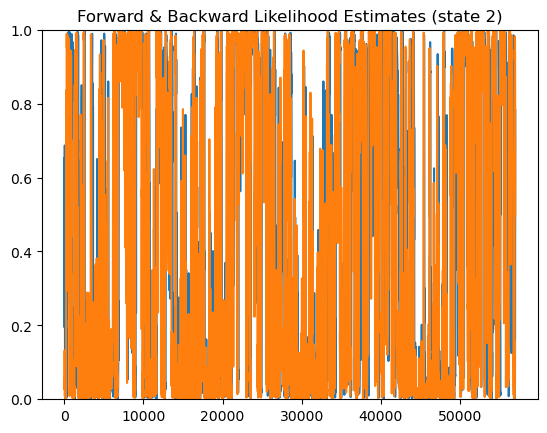

{'pi': tensor([0.5044, 0.4956]), 'A': tensor([[0.9990, 0.0010],
        [0.0010, 0.9990]])}


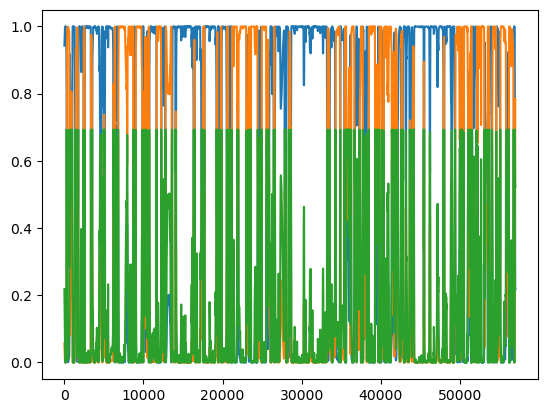

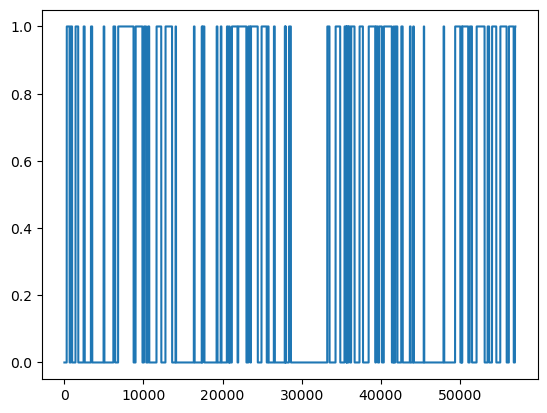

tensor(0.1734)
tensor(0.0454)
tensor([0.4296, 0.4296])
Batch 1(Minibatch 15): MSE loss:2.37


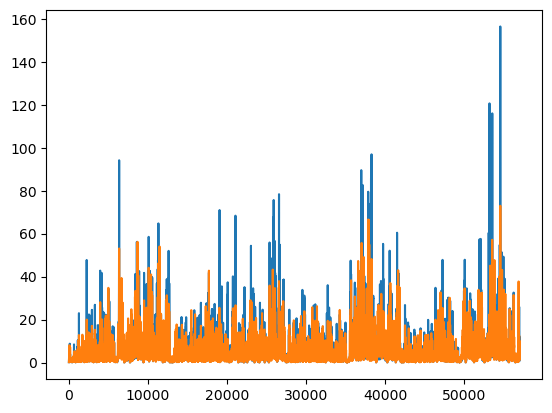

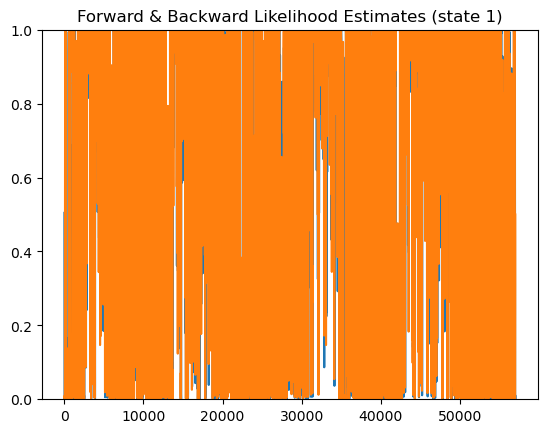

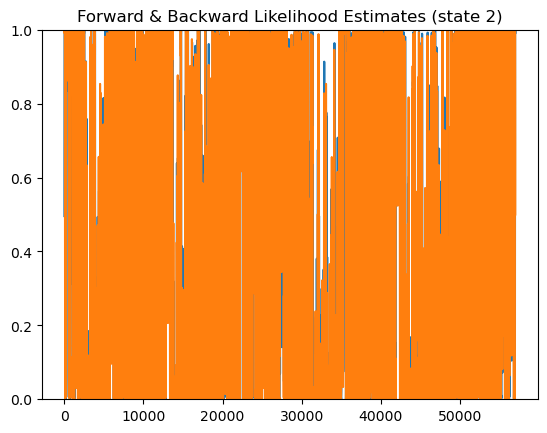

{'pi': tensor([0.4994, 0.5006]), 'A': tensor([[0.9989, 0.0011],
        [0.0011, 0.9989]])}


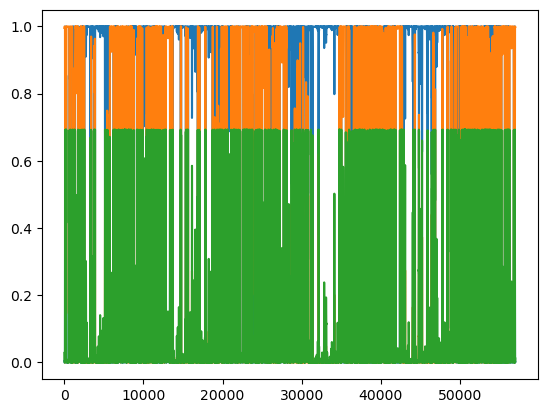

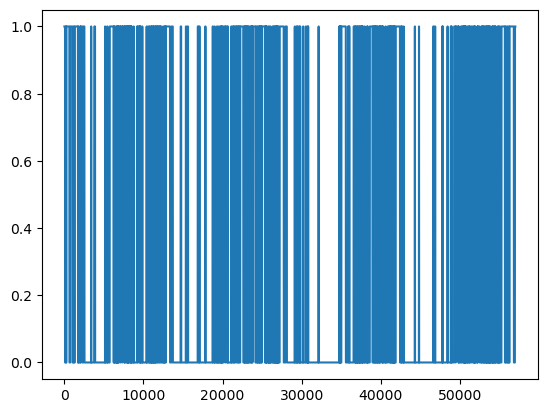

tensor(0.1035)
tensor(0.0032)
tensor([0.4393, 0.4393])
Batch 2(Minibatch 30): MSE loss:1.24
Batch 3(Minibatch 45): MSE loss:0.59
Batch 4(Minibatch 60): MSE loss:0.41
Batch 5(Minibatch 75): MSE loss:0.22
Batch 6(Minibatch 90): MSE loss:0.16
Batch 7(Minibatch 105): MSE loss:0.05
Batch 8(Minibatch 120): MSE loss:0.04
Batch 9(Minibatch 135): MSE loss:0.05
Batch 10(Minibatch 150): MSE loss:0.04
Batch 11(Minibatch 165): MSE loss:0.03
Batch 12(Minibatch 180): MSE loss:0.05
Batch 13(Minibatch 195): MSE loss:0.04
Batch 14(Minibatch 210): MSE loss:0.03
Batch 15(Minibatch 225): MSE loss:0.03
Batch 16(Minibatch 240): MSE loss:0.03
Batch 17(Minibatch 255): MSE loss:0.02
Batch 18(Minibatch 270): MSE loss:0.03
Batch 19(Minibatch 285): MSE loss:0.03
Batch 20(Minibatch 300): MSE loss:0.03
Batch 21(Minibatch 315): MSE loss:0.02
Batch 22(Minibatch 330): MSE loss:0.02
Batch 23(Minibatch 345): MSE loss:0.03
Batch 24(Minibatch 360): MSE loss:0.02
	Unaligned State Accuracy: 0.35789584466155655
[[0.52232064 0

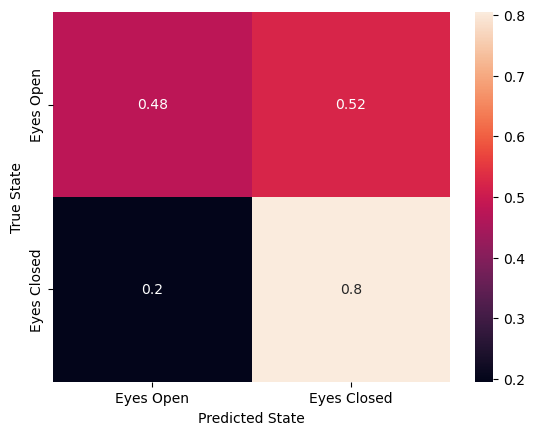

Model Number: 7
	Final Loss: 0.01978154294192791
	State Accuracy: 0.6421041553384434
	Alternate State Accuracy: 0.6411379288559457
	Random State Accuracy: 0.5330550244689621
	Kmeans State Accuracy: 0.5320552174141833
(57045,)


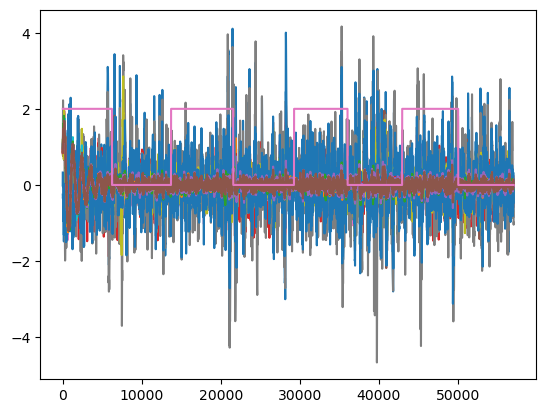

[0 0 0 ... 1 1 1]


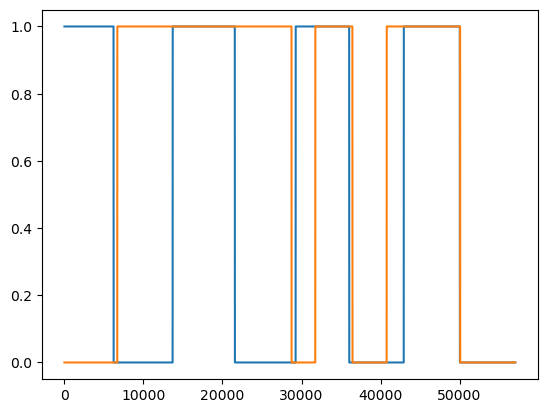

None Training set size: 3801


/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 10 worker processes in total. Our suggested max number of worker in current system is 8 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 10 worker processes in total. Our suggested max number of worker in current system is 8 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.

Batch 0(Minibatch 0): MSE loss:3.18


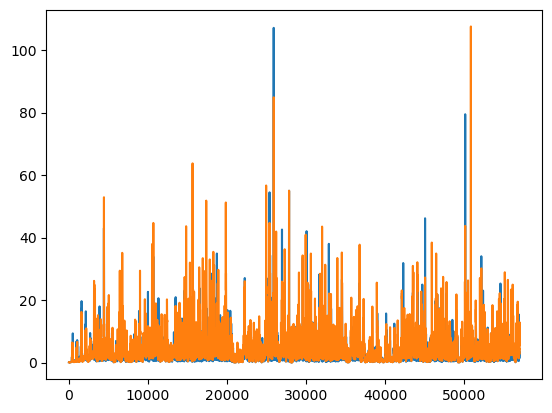

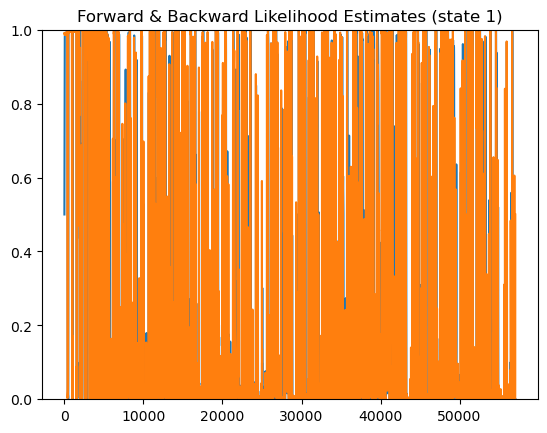

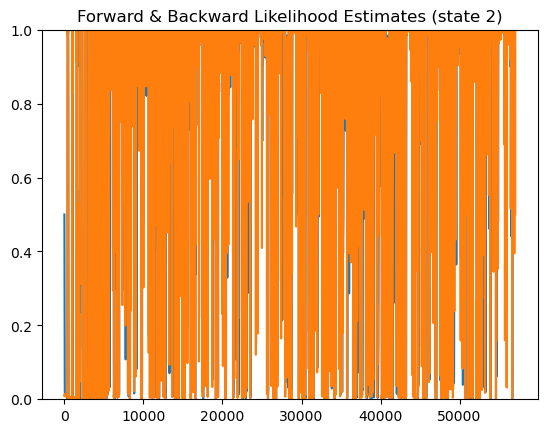

{'pi': tensor([0.5049, 0.4951]), 'A': tensor([[0.9990, 0.0010],
        [0.0011, 0.9989]])}


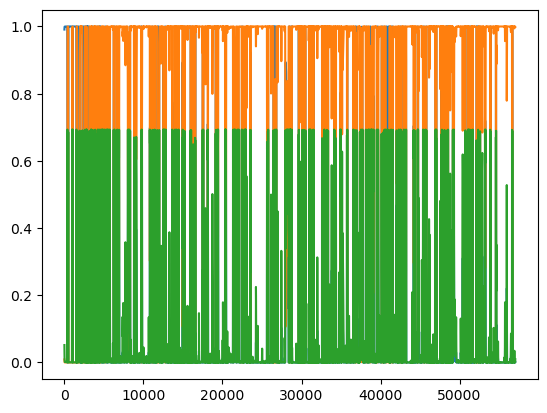

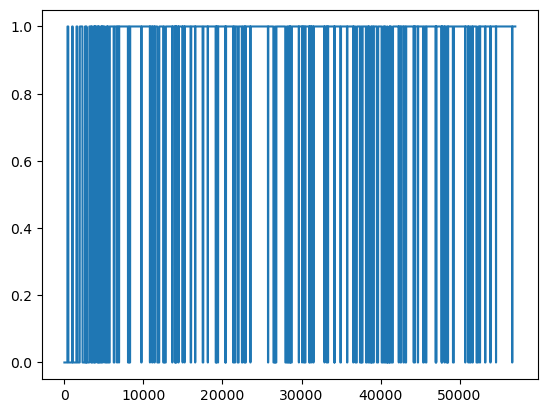

tensor(0.0811)
tensor(0.0004)
tensor([0.3618, 0.3618])
Batch 1(Minibatch 15): MSE loss:1.10
Batch 2(Minibatch 30): MSE loss:0.61
Batch 3(Minibatch 45): MSE loss:0.32
Batch 4(Minibatch 60): MSE loss:0.24
Batch 5(Minibatch 75): MSE loss:0.17
Batch 6(Minibatch 90): MSE loss:0.15
Batch 7(Minibatch 105): MSE loss:0.11
Batch 8(Minibatch 120): MSE loss:0.11
Batch 9(Minibatch 135): MSE loss:0.10
Batch 10(Minibatch 150): MSE loss:0.07
Batch 11(Minibatch 165): MSE loss:0.05
Batch 12(Minibatch 180): MSE loss:0.04
Batch 13(Minibatch 195): MSE loss:0.04
Batch 14(Minibatch 210): MSE loss:0.03
Batch 15(Minibatch 225): MSE loss:0.03
Batch 16(Minibatch 240): MSE loss:0.03
Batch 17(Minibatch 255): MSE loss:0.02
Batch 18(Minibatch 270): MSE loss:0.02
Batch 19(Minibatch 285): MSE loss:0.02
Batch 20(Minibatch 300): MSE loss:0.02
Batch 21(Minibatch 315): MSE loss:0.02
Batch 22(Minibatch 330): MSE loss:0.02
Batch 23(Minibatch 345): MSE loss:0.02
Batch 24(Minibatch 360): MSE loss:0.01
	Unaligned State Accurac

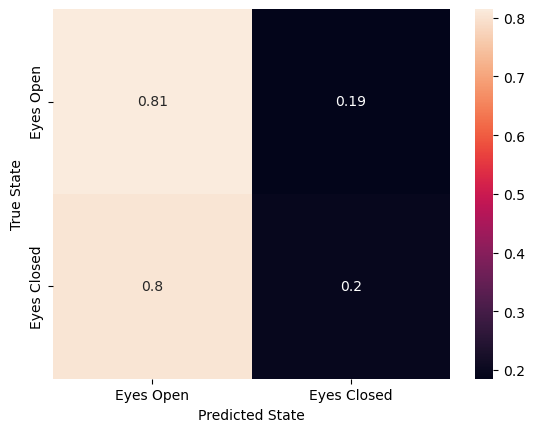

Model Number: 8
	Final Loss: 0.014622284099459648
	State Accuracy: 0.5116311683758437
	Alternate State Accuracy: 0.5054455840655171
	Random State Accuracy: 0.553159786133754
	Kmeans State Accuracy: 0.5061618020860724
(58619,)


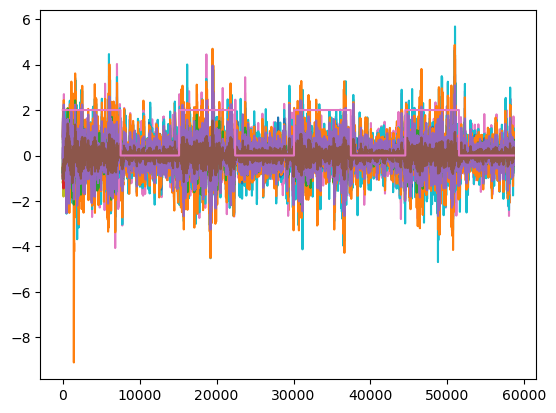

[0 0 0 ... 0 0 0]


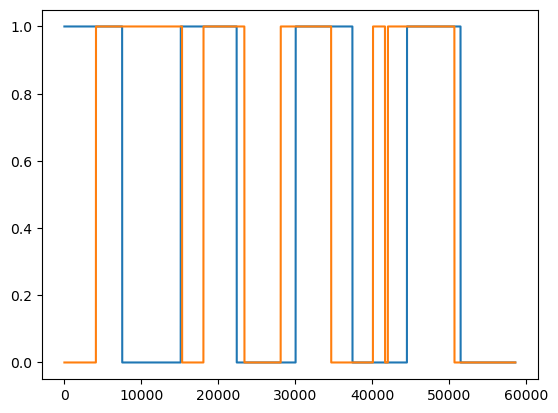

None Training set size: 3906


/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 10 worker processes in total. Our suggested max number of worker in current system is 8 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 10 worker processes in total. Our suggested max number of worker in current system is 8 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.

Batch 0(Minibatch 0): MSE loss:4.94


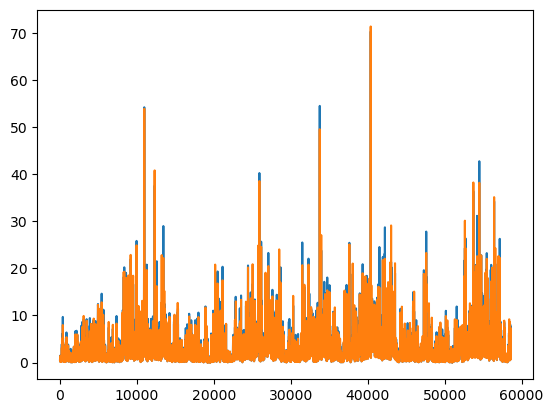

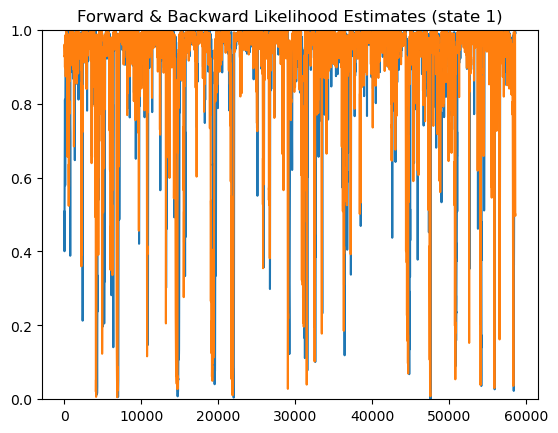

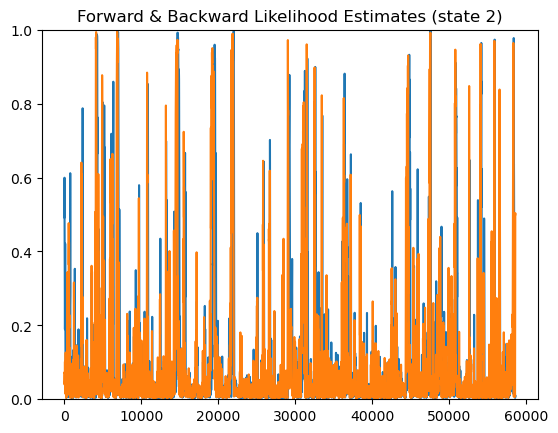

{'pi': tensor([0.5043, 0.4957]), 'A': tensor([[9.9894e-01, 1.0563e-03],
        [9.9237e-04, 9.9901e-01]])}


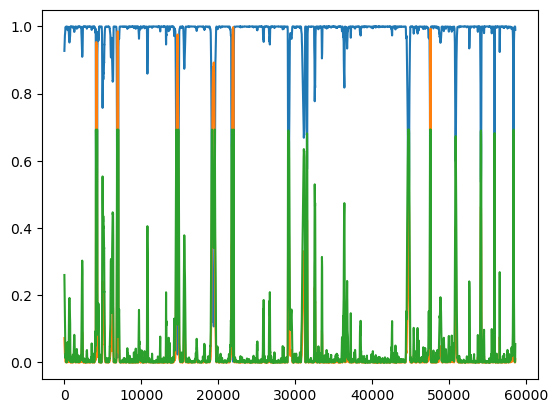

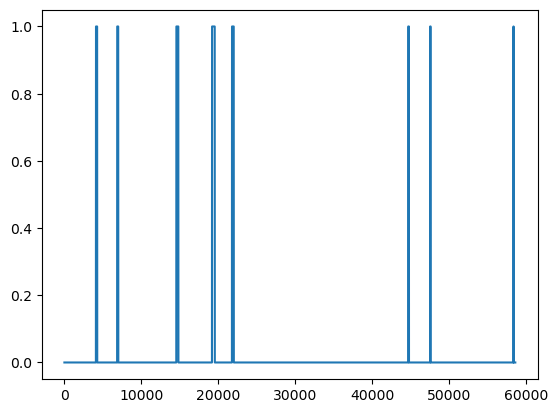

tensor(0.0555)
tensor(0.0055)
tensor([0.1354, 0.1354])
Batch 1(Minibatch 15): MSE loss:1.57


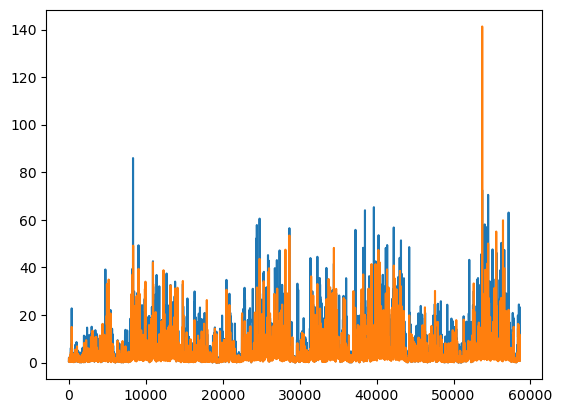

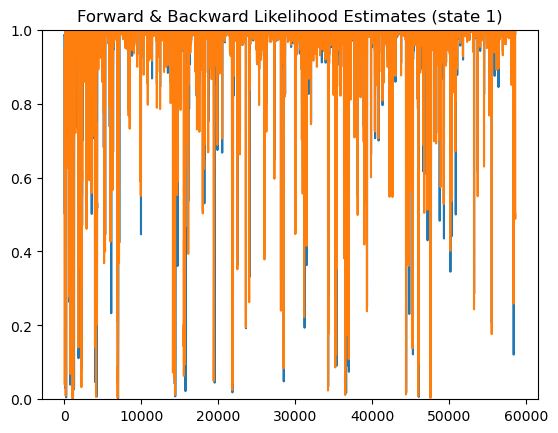

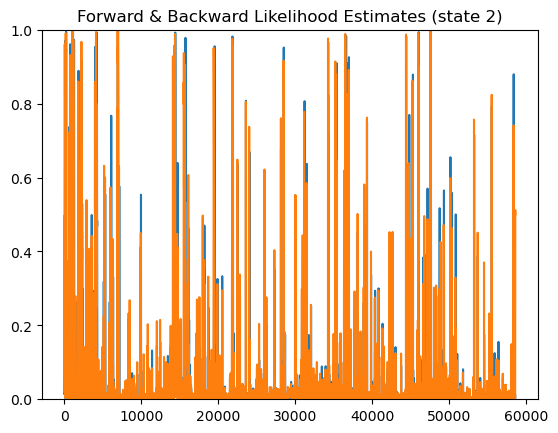

[0 0 0 ... 0 0 0]


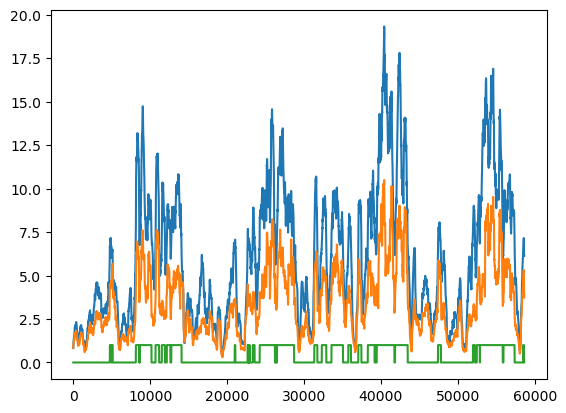

{'pi': tensor([0.5087, 0.4913]), 'A': tensor([[9.9882e-01, 1.1828e-03],
        [9.8459e-04, 9.9901e-01]])}


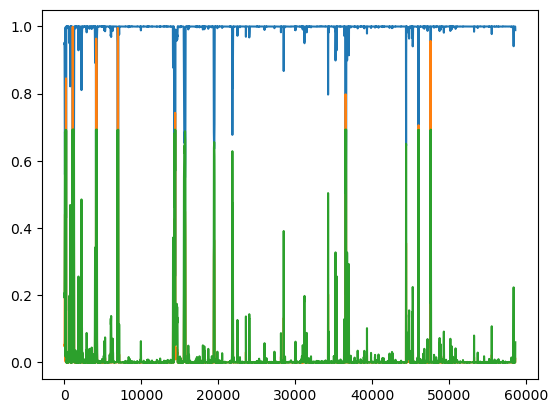

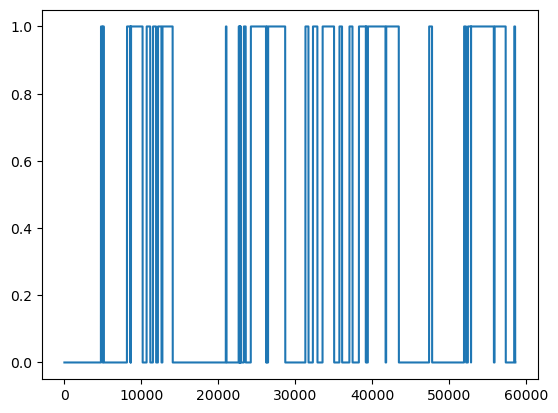

tensor(0.0208)
tensor(0.0001)
tensor([0.0911, 0.0911])
Batch 2(Minibatch 30): MSE loss:1.21


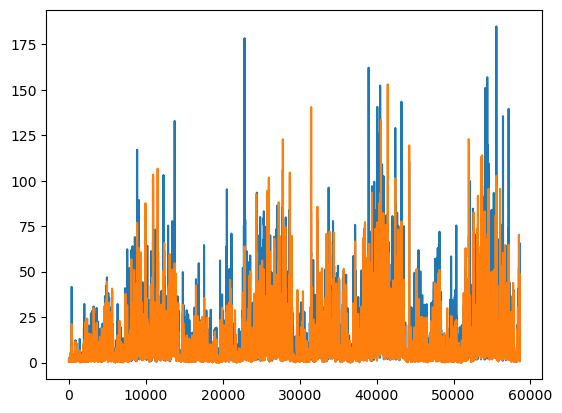

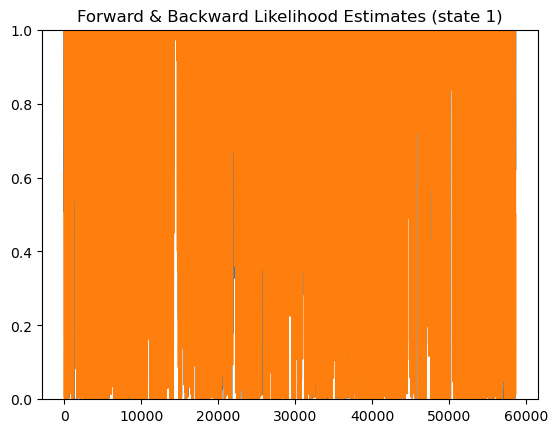

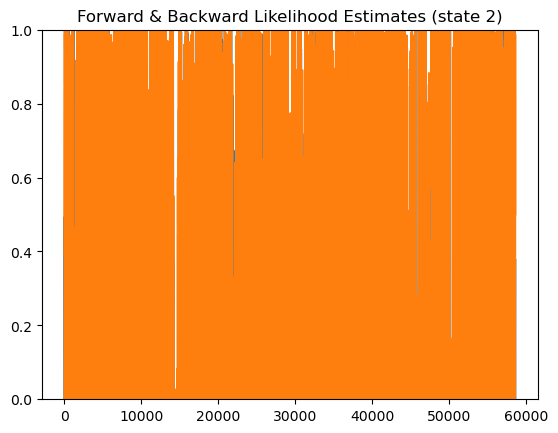

{'pi': tensor([0.5135, 0.4865]), 'A': tensor([[0.9986, 0.0014],
        [0.0010, 0.9990]])}


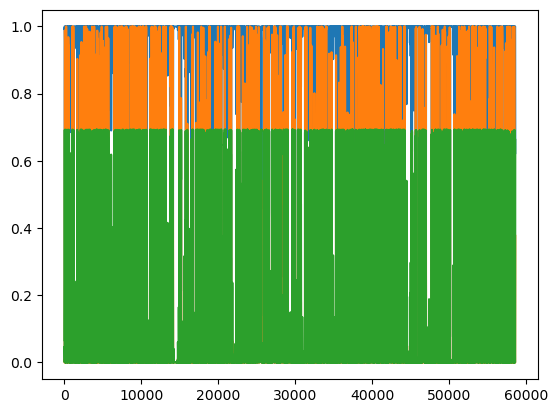

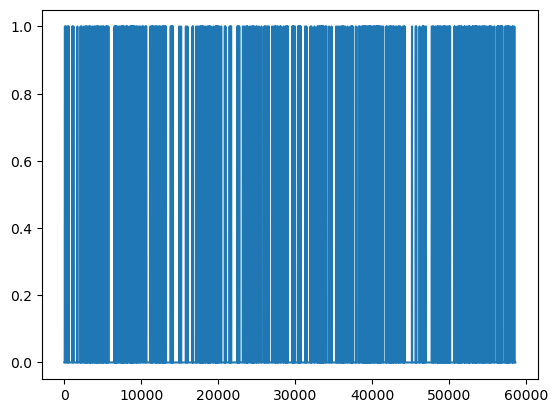

tensor(0.1187)
tensor(0.0055)
tensor([0.3378, 0.3378])
Batch 3(Minibatch 45): MSE loss:0.61
Batch 4(Minibatch 60): MSE loss:0.33
Batch 5(Minibatch 75): MSE loss:0.21
Batch 6(Minibatch 90): MSE loss:0.10
Batch 7(Minibatch 105): MSE loss:0.06
Batch 8(Minibatch 120): MSE loss:0.05
Batch 9(Minibatch 135): MSE loss:0.04
Batch 10(Minibatch 150): MSE loss:0.04
Batch 11(Minibatch 165): MSE loss:0.03
Batch 12(Minibatch 180): MSE loss:0.03
Batch 13(Minibatch 195): MSE loss:0.03
Batch 14(Minibatch 210): MSE loss:0.03
Batch 15(Minibatch 225): MSE loss:0.03
Batch 16(Minibatch 240): MSE loss:0.02
Batch 17(Minibatch 255): MSE loss:0.02
Batch 18(Minibatch 270): MSE loss:0.02
Batch 19(Minibatch 285): MSE loss:0.02
Batch 20(Minibatch 300): MSE loss:0.02
Batch 21(Minibatch 315): MSE loss:0.02
Batch 22(Minibatch 330): MSE loss:0.02
Batch 23(Minibatch 345): MSE loss:0.02
Batch 24(Minibatch 360): MSE loss:0.01
	Unaligned State Accuracy: 0.464132789709821
[[0.78428513 0.21571487]
 [0.85994302 0.14005698]]
	H

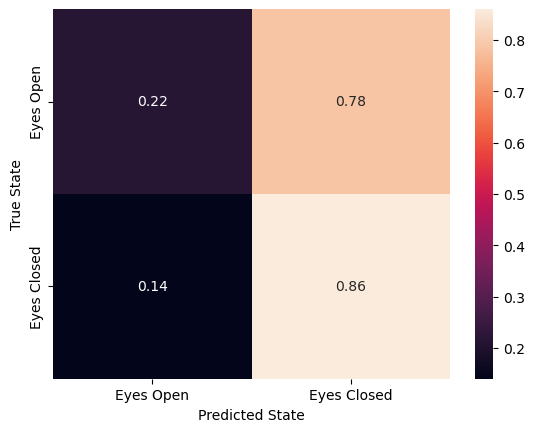

Model Number: 9
	Final Loss: 0.01850561797618866
	State Accuracy: 0.5358672102901789
	Alternate State Accuracy: 0.5378289415478004
	Random State Accuracy: 0.5728006277828008
	Kmeans State Accuracy: 0.5037956976406966


In [4]:
#### Create empty list to hold fit models and dict to hold correlations
fit_models_mod = n_models * [None]

pop_stats_HMMINDy = dict()
pop_stats_HMMINDy['state_accuracy'] = np.empty((n_models,))
pop_stats_HMMINDy['rand_state_accuracy'] = np.empty((n_models,))
pop_stats_HMMINDy['kmeans_state_accuracy'] = np.empty((n_models,))
for i in range(n_models):
    true_models_mod[i] = scipy.io.loadmat(f'mat_files_alpha/0.5-12Hz/subject_{i+1:02d}.mat')
    # Extract necessary true model params (H, Q, R are used for fitting; W and Gamma are used for fit evaluation and mask calculation)
    true_model = true_models_mod[i]['data_str'] #[0]
    data = true_model['data'][0][0]
    #data = data[:60000,:]
    #true_model = scipy.io.loadmat('../MINDy_mod_paper/anesthesia-matformat/subj'+str(i+1)+'_full.mat')
    #data = true_model['full_data'].T #data_str['full_data']
    #mod_ind_true = np.squeeze(true_model['GammaIndHist'])
    #data = scipy.stats.zscore(data)
    data_ind = np.arange(data.shape[0])
    data = np.hstack((data,data_ind[:,None]))
    P0 = P0_scale * np.eye(H.shape[1])

    # Initialize fit model
    #init_model_mod = HMMINDyCore.init(H, Q, R, W_mask, n_HMM=nS, fix_Gamma=False, fix_Se=False, fix_Ve=False, fix_Si=True, fix_Vi=True, Si_fixed_value=1, Vi_fixed_value=0, param_range=param_range, device=device,
                                      #rand_scale=1e-4,stay_prob=0.999)
    init_model_mod = HMMINDyCore.init(H, Q, R, nS, nPop=nPop, W_mask=W_mask, fixGamma=False, fix_Se=False, fix_Ve=False, fix_Si=True, fix_Vi=True, Si_fixed_value=1, Vi_fixed_value=0, param_range=param_range, device=device, 
                                      rand_scale=1e-4,stay_prob=0.999)

    # Initialize optimizer with fit model
    optimizer = torch.optim.AdamW(init_model_mod.parameters(), lr=lr, betas=betas, weight_decay=weight_decay, fused=False, amsgrad=amsgrad)

    # Plot data and true model index

    mod_ind_true = np.squeeze(true_model['mod_ind_hist'][0][0])
    #mod_ind_true = mod_ind_true[:60000]
    '''
    fig, axes = plt.subplots(int(nChan/2),2,figsize=(10,70))
    for ch in range(int(nChan/2)):
        axes[ch,0].plot(data[:,2*ch])
        axes[ch,0].plot((2*mod_ind_true))
        axes[ch,0].set_ylim([-10, 10])
        axes[ch,1].plot(data[:,2*ch+1])
        axes[ch,1].plot((2*mod_ind_true))
        axes[ch,1].set_ylim([-10, 10])
    '''
    #print(true_model['mod_ind_hist'][0][0].shape)
    plt.figure()
    plt.plot(data[:,0:nChan])
    #plt.show()
    print(mod_ind_true.shape)
    plt.plot((2*mod_ind_true))
    plt.show()

    '''
    pca = PCA(n_components=4)
    pca.fit(data[:,0:nChan])
    data_red = pca.transform(data[:,0:nChan])
    data_red = np.hstack((data_red,data_ind[:,None]))
    print(pca.explained_variance_ratio_)
    print(data_red.shape)

    fig, axes = plt.subplots(2,2,figsize=(10,10))
    axes[0,0].plot(data_red[:,0])
    axes[0,0].plot(2*mod_ind_true)
    axes[0,1].plot(data_red[:,1])
    axes[0,1].plot(2*mod_ind_true)
    axes[1,0].plot(data_red[:,2])
    axes[1,0].plot(2*mod_ind_true)
    axes[1,1].plot(data_red[:,2])
    axes[1,1].plot(2*mod_ind_true)
    plt.show()
    '''
    # K means cluster data to get initial transitions estimate
    kmeans = KMeans(n_clusters=2,n_init=5).fit(data[:,0:nChan])
    print(kmeans.labels_)
    #plt.plot(kmeans.labels_)
    #plt.plot(np.std(data[:,0:nChan],1))
    #plt.show()
    #data_init_fit = np.hstack((data[:,0:20],kmeans.labels_[:,None]))

    # Fit initial model
    #mod_model, train_info = train_mod_data_MSE(data_init_fit,
    #                                    init_model_mod, 10,
    #                                    stack_interval,
    #                                    warm_up_step,
    #                                    kf_step, rec_step,
    #                                    optimizer, P0,
    #                                    clipping_grad_norm=clipping_grad_norm,
    #                                    clipping_grad_norm_value=clipping_grad_norm_value,
    #                                    device=device,
    #                                    prepare_data_loader_func=prepare_data_loader)
    
    tmp = create_synth_HMMINDy(nChan,nPop,nS,tRun=data.shape[0]+1,pStay=0.99985)
    Gamma_ind_hist = tmp['mod_ind_hist']
    plt.plot(mod_ind_true)
    plt.plot(Gamma_ind_hist)
    #plt.plot(kmeans.labels_)
    plt.savefig("mod_ind_true.svg")
    plt.show()

    
    # Fit model
    mod_model, train_info, mod_ind_fit = train_hmmindy_data_MSE(data,
                                        init_model_mod, n_batch,
                                        stack_interval,
                                        warm_up_step,
                                        kf_step, rec_step,
                                        optimizer, P0,
                                        Gamma_ind_hist=Gamma_ind_hist,
                                        clipping_grad_norm=clipping_grad_norm,
                                        clipping_grad_norm_value=clipping_grad_norm_value,
                                        device=device,
                                        prepare_data_loader_func=prepare_data_loader)
    mod_ind_fit = mod_ind_fit.cpu().numpy()
    # BEGIN JAKE CODE
    # Fit labels are not aligned to the true labels yet (that happens below), so this can be < 0.5
    print(f"\tUnaligned State Accuracy: {np.sum((mod_ind_fit == mod_ind_true))/mod_ind_true.shape[0]}")
    # END JAKE CODE
    
    
    '''
    # Extract W/Gamma matrices & components
    Wee_fit = mod_model.Wee.detach().cpu().numpy()
    Wei_fit = mod_model.Wei.detach().cpu().numpy()
    Wie_fit = mod_model.Wie.detach().cpu().numpy() #local blocks (diag vector for nPop=2)
    Wii_fit = mod_model.Wii.detach().cpu().numpy() #local blocks (diag vector for nPop=2)
    # JAKE: the .W property assembles the full channel-major W from the fit blocks
    W_fit = mod_model.W.detach().cpu().numpy()
    #W_fit = np.hstack([np.vstack([Wee_fit,Wei_fit]),-np.vstack([np.diag(Wie_fit),np.diag(Wii_fit)])])
    # JAKE: the .Gamma property is the full channel-major Gamma stack (kept unsigned,
    # matching create_synth_data.py's abs(Wmask)*...); slice its E/I blocks with
    # E_idx/I_idx from pop_layout()
    Gamma_fit = mod_model.Gamma.detach().cpu().numpy()
    Gammaee_fit = Gamma_fit[np.ix_(E_idx, E_idx)]
    Gammaei_fit = Gamma_fit[np.ix_(I_idx, E_idx)]
    #Gamma_fit = np.empty((nPop*nChan,nPop*nChan,nS))
    #for j in range(nS):
    #    Gamma_fit[:,:,j] = np.hstack([np.vstack([Gammaee_fit[:,:,j],Gammaei_fit[:,:,j]]),-np.vstack([np.diag(np.squeeze(Gammaie_fit[:,j])),np.diag(np.squeeze(Gammaii_fit[:,j]))])])

    # Compute W/Gamma correlations
    corr_W = np.corrcoef(W_fit.flatten(),W_truth.flatten())[0,1]
    corr_Wee = np.corrcoef(Wee_fit.flatten(),W_truth[np.ix_(E_idx,E_idx)].flatten())[0,1]
    corr_Wei = np.corrcoef(Wei_fit.flatten(),W_truth[np.ix_(I_idx,E_idx)].flatten())[0,1]
    #corr_Wee = np.corrcoef(Wee_fit.flatten(),W_truth[:Wee_fit.shape[0],:Wee_fit.shape[1]].flatten())[0,1]
    #corr_Wei = np.corrcoef(Wei_fit.flatten(),W_truth[Wee_fit.shape[0]:,:Wei_fit.shape[1]].flatten())[0,1]
    corr_Gamma = np.zeros((nS,))
    corr_Gamma_ee = np.zeros((nS,))
    corr_Gamma_ei = np.zeros((nS,))
    for j in range(nS):
        corr_Gamma[j] = np.corrcoef(Gamma_fit[:,:,j].flatten(),Gamma_truth[:,:,j].flatten())[0,1]
        corr_Gamma_ee[j] = np.corrcoef(Gammaee_fit[:,:,j].flatten(),Gamma_truth[np.ix_(E_idx,E_idx)][:,:,j].flatten())[0,1]
        corr_Gamma_ei[j] = np.corrcoef(Gammaei_fit[:,:,j].flatten(),Gamma_truth[np.ix_(I_idx,E_idx)][:,:,j].flatten())[0,1]
    '''

    
    # Save fit model and stats into list
    fit_model = dict()
    fit_model['model'] = mod_model
    fit_model['train_info'] = train_info
    fit_model['mod_ind_fit'] = mod_ind_fit
    fit_models_mod[i] = fit_model
    
    '''
    fit_model['corrs'] = dict()
    fit_model['corrs']['W'] = corr_W
    fit_model['corrs']['Wee'] = corr_Wee
    fit_model['corrs']['Wei'] = corr_Wei
    fit_model['corrs']['Gamma'] = corr_Gamma
    fit_model['corrs']['Gammaee'] = corr_Gamma_ee
    fit_model['corrs']['Gammaei'] = corr_Gamma_ei
    fit_models_mod[i] = fit_model
    # Save correlation values into population dictionary
    pop_corrs_MINDy_mod['W_corr'][i] = corr_W
    pop_corrs_MINDy_mod['Wee_corr'][i] = corr_Wee
    pop_corrs_MINDy_mod['Wei_corr'][i] = corr_Wei
    pop_corrs_MINDy_mod['Gamma_corr'][i,:] = corr_Gamma
    pop_corrs_MINDy_mod['Gammaee_corr'][i,:] = corr_Gamma_ee
    pop_corrs_MINDy_mod['Gammaei_corr'][i,:] = corr_Gamma_ei
    '''
    
    # BEGIN JAKE CODE
    # state_accuracy / rand_state_accuracy / kmeans_state_accuracy are now saved after
    # the Hungarian alignment below; saving them here recorded unaligned values
    # END JAKE CODE
    
    
    # Confusion matrix
    conf_mat = np.zeros((2,nS))
    for j in range(2):
        for k in range(nS):
            conf_mat[j,k] = np.sum(np.logical_and(mod_ind_true==j, mod_ind_fit==k))/np.sum(mod_ind_true==j)
    #conf_mat = np.vstack((conf_mat,np.ones((1,nS))))
    print(conf_mat)

    # BEGIN JAKE CODE
    # Hungarian algorithm: HMM state labels are arbitrary (fit state 0 may be true
    # state 1), so match fit labels to true labels before scoring. Matching on
    # timepoint counts maximizes raw accuracy, so with 2 states it is always >= 0.5.
    labels, mod_ind_fit = align_to_truth(mod_ind_true, mod_ind_fit, 2, nS)
    print(f"\tHungarian matches (true state, fit state): {labels}")

    # Save stats only after alignment. The random and K-means baselines get the same
    # alignment so the comparison against HM-MINDy is fair.
    pop_stats_HMMINDy['state_accuracy'][i] = np.sum((mod_ind_fit == mod_ind_true))/mod_ind_true.shape[0]
    _, rand_ind_aligned = align_to_truth(mod_ind_true, Gamma_ind_hist, 2, nS)
    _, kmeans_ind_aligned = align_to_truth(mod_ind_true, kmeans.labels_, 2, 2)
    pop_stats_HMMINDy['rand_state_accuracy'][i] = np.sum((rand_ind_aligned == mod_ind_true))/mod_ind_true.shape[0]
    pop_stats_HMMINDy['kmeans_state_accuracy'][i] = np.sum((kmeans_ind_aligned == mod_ind_true))/mod_ind_true.shape[0]
    # END JAKE CODE

    '''
    plt.figure()
    plt.plot(mod_ind_true)
    plt.plot(mod_ind_fit)
    ax = plt.gca()
    ax.set_yticks([0, 1])
    ax.set_yticklabels(['Eyes Open','Eyes Closed'])
    ax.set_xlabel('Time Points')
    plt.savefig(f'images/state_id_{i}.svg')
    plt.show()
    '''
    
    # Confusion matrix
    conf_mat = np.zeros((2,nS))
    for j in range(2):
        for k in range(nS):
            conf_mat[j,k] = np.sum(np.logical_and(mod_ind_true==j, mod_ind_fit==k))/np.sum(mod_ind_true==j)
    print(conf_mat)
    sns.heatmap(conf_mat,annot=True)
    ax = plt.gca()
    #ax.set_xticklabels(['Eyes Open','Eyes Closed','State 3'])
    ax.set_xticklabels(['Eyes Open','Eyes Closed'])
    ax.set_yticklabels(['Eyes Open','Eyes Closed'])
    ax.set_ylabel('True State')
    ax.set_xlabel('Predicted State')
    plt.savefig(f'images/conf_mat_{i}.svg')
    plt.show()
    
    # Display stats for current fit
    print(f"Model Number: {i}")
    print(f"\tFinal Loss: {train_info['train_MSE_losses_record_mini_batch'][-1]}")
    print(f"\tState Accuracy: {np.sum((mod_ind_fit == mod_ind_true))/mod_ind_true.shape[0]}")
    print(f"\tAlternate State Accuracy: {0.5 * np.sum(np.logical_and(mod_ind_true==0, mod_ind_fit==0))/np.sum(mod_ind_true==0) + 0.5 * np.sum(np.logical_and(mod_ind_true==1, mod_ind_fit==1))/np.sum(mod_ind_true==1)}")
    
    # BEGIN JAKE CODE
    # Baselines are aligned to the true labels the same way as the fit (Hungarian step above)
    print(f"\tRandom State Accuracy: {pop_stats_HMMINDy['rand_state_accuracy'][i]}")
    print(f"\tKmeans State Accuracy: {pop_stats_HMMINDy['kmeans_state_accuracy'][i]}")
    # END JAKE CODE
    '''
    print(f"\tW Correlation: {corr_W}")
    print(f"\tWee Correlation: {corr_Wee}")
    print(f"\tWei Correlation: {corr_Wei}")
    for j in range(nS):
        print(f"\tGamma{j} Correlation: {corr_Gamma[j]}")
        print(f"\tGamma{j}ee Correlation: {corr_Gamma_ee[j]}")
        print(f"\tGamma{j}ei Correlation: {corr_Gamma_ei[j]}")
    '''

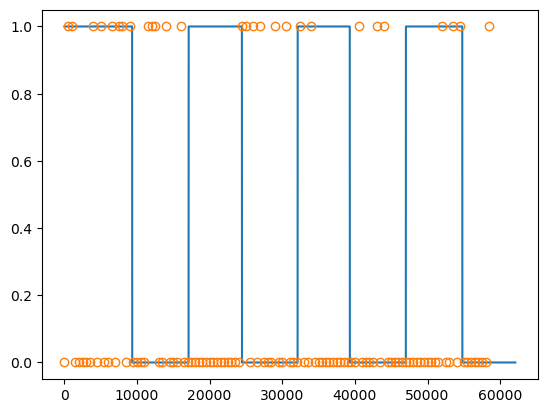

'\nprint(mod_model.HMM[\'A\'])\nprint(np.sum(mod_ind_fit.numpy() == mod_ind_true)/mod_ind_true.shape[0])\nprint(f"\tW Correlation: {corr_W}")\nprint(f"\tWee Correlation: {corr_Wee}")\nprint(f"\tWei Correlation: {corr_Wei}")\nfor j in range(nS):\n    print(f"\tGamma{j} Correlation: {corr_Gamma[j]}")\n    print(f"\tGamma{j}ee Correlation: {corr_Gamma_ee[j]}")\n    print(f"\tGamma{j}ei Correlation: {corr_Gamma_ei[j]}")\n'

In [10]:
true_model = scipy.io.loadmat(f'mat_files_alpha/8-12Hz/subject_{19+1:02d}.mat')
true_model = true_model['data_str']
mod_ind_true = np.squeeze(true_model['mod_ind_hist'][0][0])
#mod_ind_true = mod_ind_true[:60000]
mod_ind_fit = fit_models_mod[n_models-1]['mod_ind_fit']
plt.figure()
plt.plot(mod_ind_true)
#plt.plot(mod_ind_fit)
plt.plot(mod_ind_fit,'o',markevery=500,fillstyle='none')
plt.savefig(f'images/state_id_{19}.svg')
plt.show()
'''
print(mod_model.HMM['A'])
print(np.sum(mod_ind_fit.numpy() == mod_ind_true)/mod_ind_true.shape[0])
print(f"\tW Correlation: {corr_W}")
print(f"\tWee Correlation: {corr_Wee}")
print(f"\tWei Correlation: {corr_Wei}")
for j in range(nS):
    print(f"\tGamma{j} Correlation: {corr_Gamma[j]}")
    print(f"\tGamma{j}ee Correlation: {corr_Gamma_ee[j]}")
    print(f"\tGamma{j}ei Correlation: {corr_Gamma_ei[j]}")
'''

Text(0, 0.5, 'MSE')

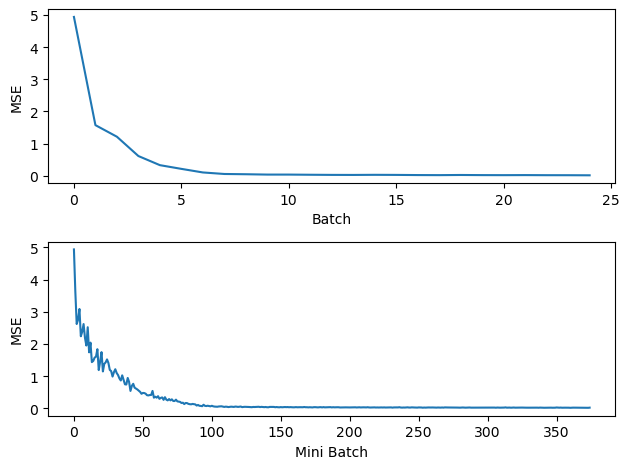

In [7]:
train_MSE=train_info['train_MSE'] # per batch includes total_size/mini_batch_size ,mini batches
train_MSE_mini_batch=train_info['train_MSE_losses_record_mini_batch']

## Plot the training loss

plt.figure(tight_layout=True)
plt.subplot(2,1,1)
plt.plot(train_MSE)
plt.xlabel("Batch")
plt.ylabel("MSE")

## Plot mini batch loss
plt.subplot(2,1,2)
plt.plot(train_MSE_mini_batch)
plt.xlabel("Mini Batch")
plt.ylabel("MSE")

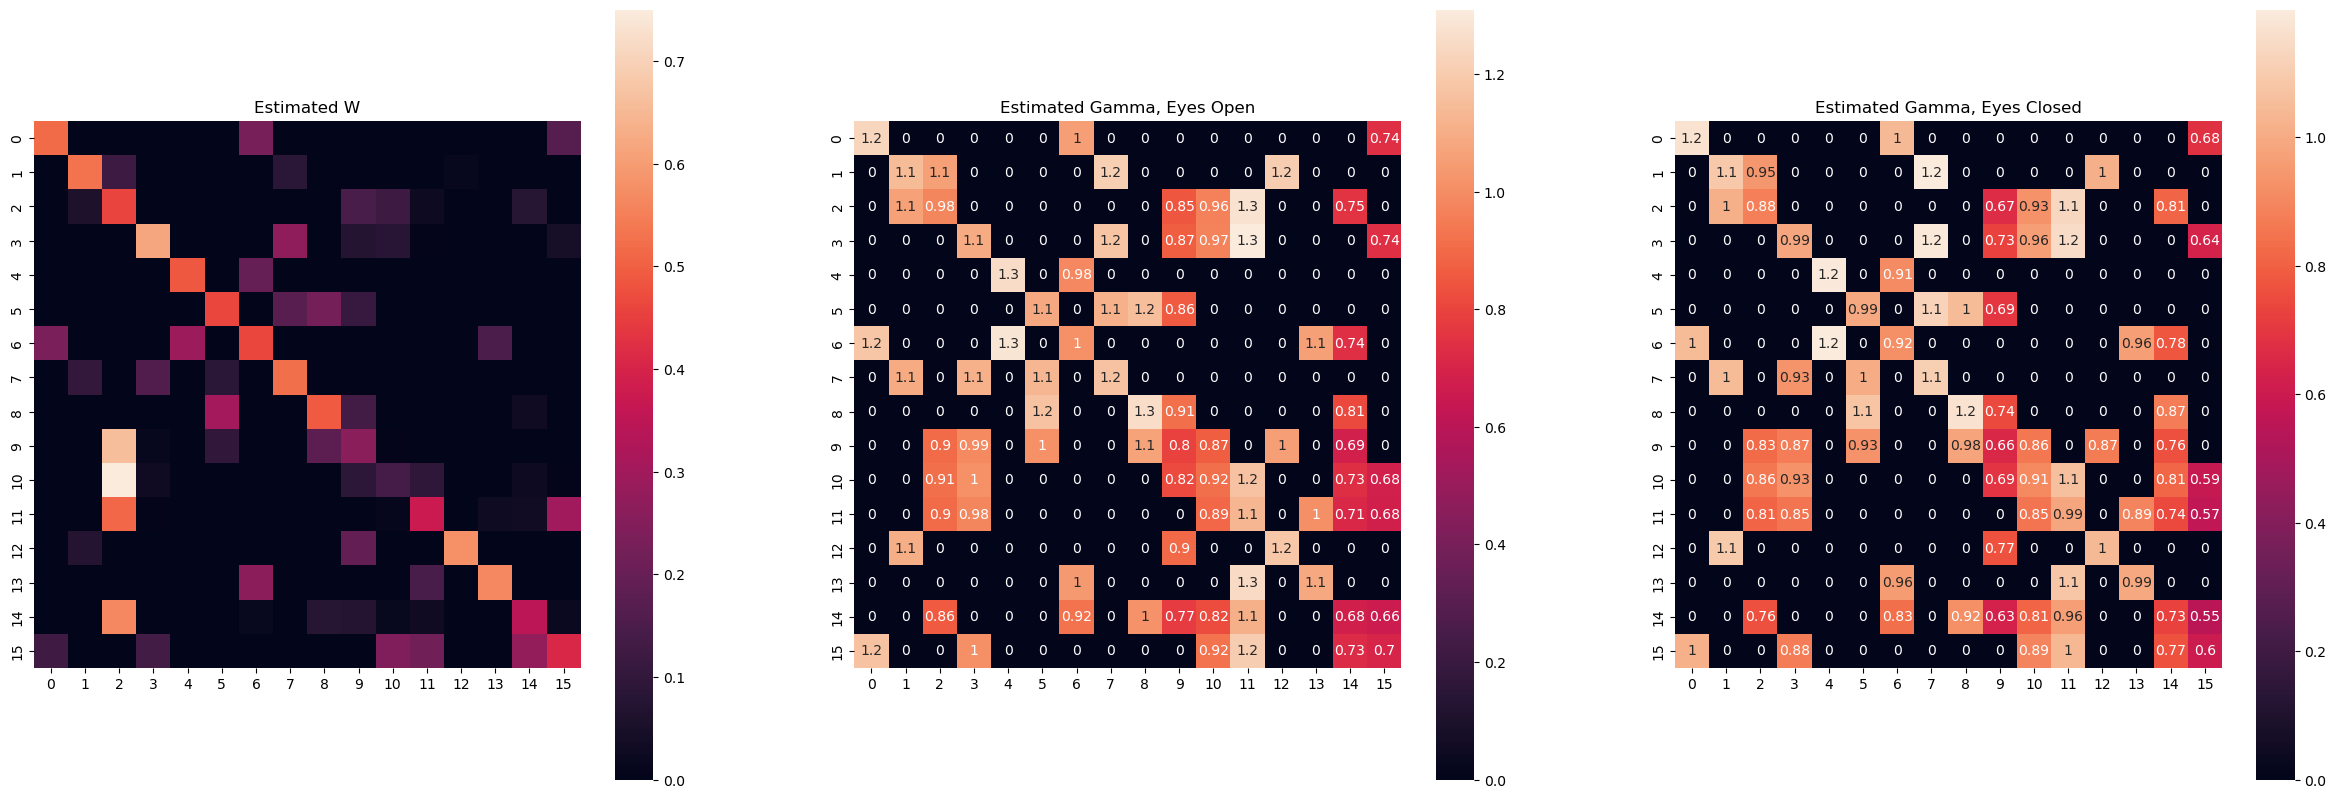

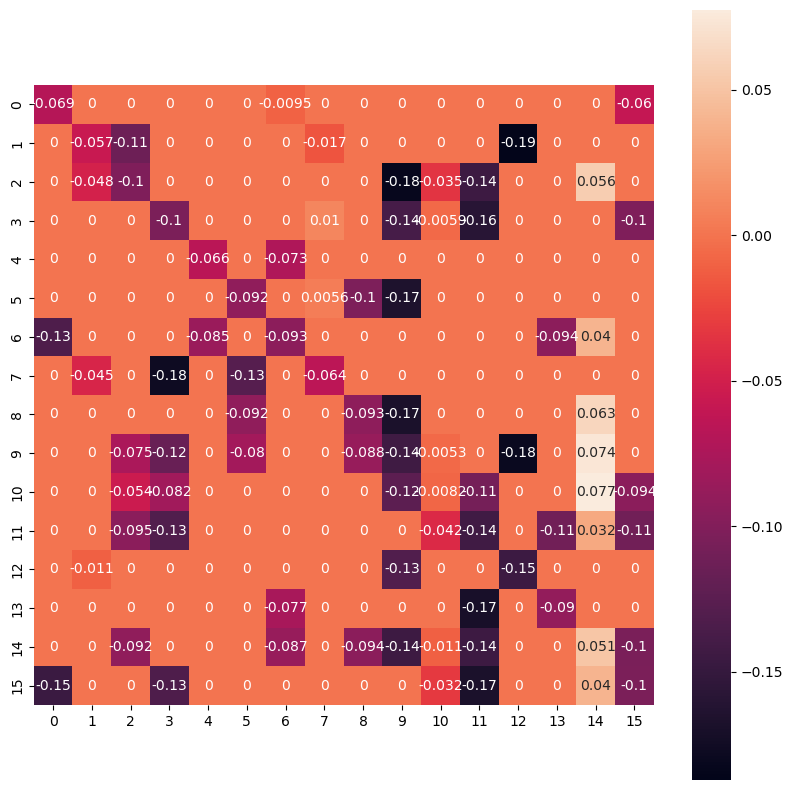

In [8]:
# Extract W/Gamma matrices & components
# JAKE: E/I indices come from each fit model's own layout (not the nPop hyperparameter),
# so this also works on models loaded from a pickle fit with a different nPop.
# EE blocks are (nChan*nE x nChan*nE).
for i in range(n_models):
    mod_model = fit_models_mod[i]
    mod_model = mod_model['model']
    _, _, E_idx_fit, I_idx_fit, _ = pop_layout(mod_model.n_chan, mod_model.n_pop_per_chan)
    if i == 0:
        Gamma_fit_pop = np.zeros((E_idx_fit.size,E_idx_fit.size,nS,n_models))
        Gamma_fit_pop_diff = np.zeros((E_idx_fit.size,E_idx_fit.size,n_models))
    Wee_fit = mod_model.Wee.detach().cpu().numpy()
    Wei_fit = mod_model.Wei.detach().cpu().numpy()
    Wie_fit = mod_model.Wie.detach().cpu().numpy() #local blocks (diag vector for nPop=2)
    Wii_fit = mod_model.Wii.detach().cpu().numpy() #local blocks (diag vector for nPop=2)
    # JAKE: the .W property assembles the full channel-major W from the fit blocks
    W_fit = mod_model.W.detach().cpu().numpy()
    #W_fit = np.hstack([np.vstack([Wee_fit,Wei_fit]),-np.vstack([np.diag(Wie_fit),np.diag(Wii_fit)])])
    # JAKE: the .Gamma property is the full channel-major Gamma stack (kept unsigned,
    # matching create_synth_data.py's abs(Wmask)*...); slice its E/I blocks with
    # E_idx/I_idx from pop_layout()
    Gamma_fit = mod_model.Gamma.detach().cpu().numpy()
    Gammaee_fit = Gamma_fit[np.ix_(E_idx_fit, E_idx_fit)]
    Gammaei_fit = Gamma_fit[np.ix_(I_idx_fit, E_idx_fit)]
    #Gamma_fit = np.empty((nPop*nChan,nPop*nChan,nS))
    #for j in range(nS):
    #    Gamma_fit[:,:,j] = np.hstack([np.vstack([Gammaee_fit[:,:,j],Gammaei_fit[:,:,j]]),-np.vstack([np.diag(np.squeeze(Gammaie_fit[:,j])),np.diag(np.squeeze(Gammaii_fit[:,j]))])])
    Gamma_fit_pop[:,:,:,i] = Gammaee_fit
    Gamma_fit_pop_diff[:,:,i] = Gammaee_fit[:,:,1] - Gammaee_fit[:,:,0]

fig,axes=plt.subplots(1,3,figsize=(30,10))
sns.heatmap(W_fit[np.ix_(E_idx_fit,E_idx_fit)],ax=axes[0],square=True,vmin=0,vmax=0.75) # JAKE: EE block
axes[0].set_title('Estimated W')
sns.heatmap(np.mean(Gamma_fit_pop[:,:,0,:],axis=2),ax=axes[1],square=True,annot=True) # JAKE: already the EE block
axes[1].set_title('Estimated Gamma, Eyes Open')
sns.heatmap(np.mean(Gamma_fit_pop[:,:,1,:],axis=2),ax=axes[2],square=True,annot=True) # JAKE: already the EE block
axes[2].set_title('Estimated Gamma, Eyes Closed')


fig = plt.figure(figsize=(10,10))
sns.heatmap(np.mean(Gamma_fit_pop_diff,axis=2),square=True,annot=True)
plt.show()

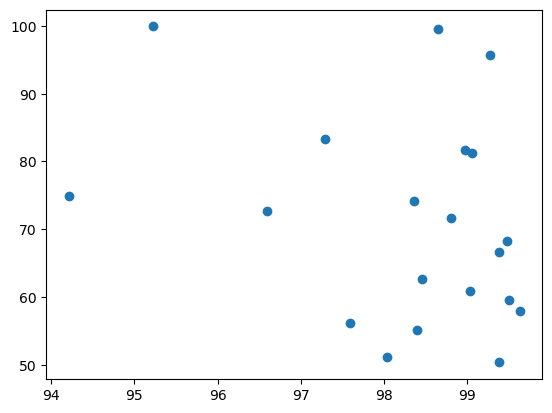

Correlation:  -0.2966044198594851


In [9]:
Gamma_corrs = [99.64, 99.48, 98.46, 97.30, 98.81, 99.51, 96.59, 99.39, 99.04, 97.59, 94.21, 98.04, 99.06, 99.28, 99.39, 98.4, 98.98, 98.66, 98.37, 95.22]
state_acc = [57.94, 68.31, 62.72, 83.29, 71.7, 59.61, 72.68, 50.33, 60.84, 56.14, 74.88, 51.17, 81.21, 95.79, 66.6, 55.19, 81.7, 99.59, 74.22, 99.93]

plt.scatter(Gamma_corrs, state_acc)
plt.show()

print('Correlation: ',np.corrcoef(Gamma_corrs,state_acc)[0,1])

## Save true and fit models to file

In [11]:
timestamp = datetime.datetime.now()
timestamp = timestamp.strftime("%m_%d_%Y_%H:%M:%S")
fit_file = 'HM-MINDy_alpha_fit_'+timestamp+'.pkl'
with open(savefilepath + fit_file, 'wb') as file:
    pickle.dump(fit_models_mod, file)

0.5831948506959636
0.5779725404210576


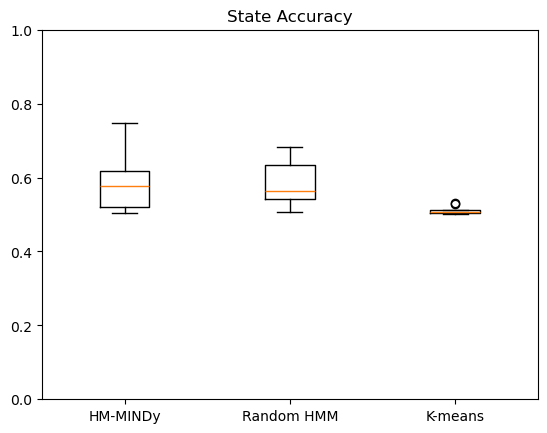

In [12]:
# BEGIN JAKE CODE
# Plot the results from this run (saved in cell 7 after Hungarian alignment)
# instead of hard-coded values from an earlier run
state_acc = pop_stats_HMMINDy['state_accuracy']
random_state_acc = pop_stats_HMMINDy['rand_state_accuracy']
kmeans_state_acc = pop_stats_HMMINDy['kmeans_state_accuracy']

# Hard-coded values from an earlier run, kept for reference:
#state_acc = np.array([0.57, 0.81, 0.66, 0.50, 0.51, 0.55, 0.71, 0.80, 0.55, 0.79, 0.62, 0.67, 0.53, 0.86, 0.73, 0.51, 0.52])
#random_state_acc = np.array([0.55,0.50,0.35,0.43,0.45,0.49,0.59,0.52,0.43,0.64,0.63,0.48,0.52,0.44,0.61,0.41,0.49,0.50,0.60,0.46])
#kmeans_state_acc = np.array([0.50,0.65,0.50,0.50,0.49,0.50,0.49,0.50,0.50,0.50,0.50,0.48,0.50,0.50,0.50,0.50,0.50,0.49,0.50,0.50])
# The two commented lines below flipped accuracies under 0.5 by hand; the Hungarian
# alignment in cell 7 now does this, so they are no longer needed
# END JAKE CODE
#pop_stats_HMMINDy['state_accuracy'][pop_stats_HMMINDy['state_accuracy']<0.5] = 1 - pop_stats_HMMINDy['state_accuracy'][pop_stats_HMMINDy['state_accuracy']<0.5]
#pop_stats_HMMINDy['kmeans_state_accuracy'][pop_stats_HMMINDy['kmeans_state_accuracy']<0.5] = 1 - pop_stats_HMMINDy['kmeans_state_accuracy'][pop_stats_HMMINDy['kmeans_state_accuracy']<0.5]
print(np.mean(state_acc))
print(np.median(state_acc))

plt.boxplot([state_acc,random_state_acc,kmeans_state_acc])
ax = plt.gca()
ax.set_ylim([0, 1])
ax.set_xticklabels(['HM-MINDy','Random HMM','K-means'])
ax.set_title('State Accuracy')
plt.savefig('images/alpha_state_accuracy.svg')
plt.show()

fig = go.Figure()
fig.add_trace(go.Violin(x=state_acc,name='HM-MINDy',box_visible=True,side='positive',points='all'))
fig.add_trace(go.Violin(x=random_state_acc,name='Random HMM',box_visible=True,side='positive',points='all'))
fig.add_trace(go.Violin(x=kmeans_state_acc,name='K Means',box_visible=True,side='positive',points='all'))
fig.update_xaxes(range=[0, 1])
fig.update_layout(title=dict(text='State Accuracy'),xaxis=dict(title=dict(text='Percent of Time Points Correctly Identified')))
#fig.write_image('alpha_state_accuracy.svg')

In [3]:
#with open('HM-MINDy_alpha_fit_07_13_2025_08:23:23.pkl','rb') as file:
    #fit_models_mod = pickle.load(file)

# JAKE: this file was saved with the old (nPop=2) HMMINDyCore, so load it through
# the legacy class; fits saved after the general-nPop rewrite use pickle.load()
with open('HM-MINDy_alpha_fit_10_19_2026_18:59:57.pkl','rb') as file:
    fit_models_mod = load_legacy_pickle(file)

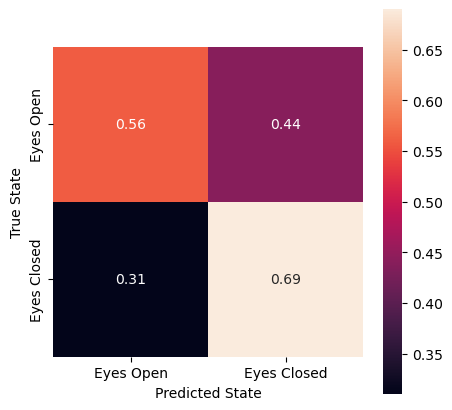

In [14]:
mean_conf_mat = [[0.56, 0.44],[0.31,0.69]]

fig = plt.figure(figsize=(5,5))
sns.heatmap(mean_conf_mat,square=True,annot=True)
ax = plt.gca()
ax.set_xticklabels(['Eyes Open','Eyes Closed'])
ax.set_yticklabels(['Eyes Open','Eyes Closed'])
ax.set_ylabel('True State')
ax.set_xlabel('Predicted State')
plt.savefig(f'images/conf_mat_mean.svg')
plt.show()